# 03 - Prévision de la demande - Approche 2 (courbes de pickup)

**PFE ENSAI 2025/2026 - Prévision de la demande & Pricing Dynamique**

Cette seconde approche aborde la prévision de la demande comme un **problème de courbes de pickup** (montée en charge) au grain fin :

- **Grain** : `ID_ETABLISSEMENT × ID_TYPE_CHAMBRE × NB_PERS_CHAMBRE × PARTENAIRE_SEG2 × DUREE_SEJOUR × SAISON × SEGMENT_DOSSIER × SEMAINE_SEJOUR × DATE_OBSERVATION`.
- **Cible** : `TARGET_PICKUP_RESTANT = VOL_FINAL - VOL_CUMUL_HIST`.
- **Snapshots lead-time** : 9 horizons (362, 180, 131, 89, 61, 33, 19, 12, 5 jours) - *Ampountolas & Legg (2025)*.
- **Validation** : rolling walk-forward sur les exercices N-3 / N-2 / N-1.
- **Modèle** : XGBoost (gradient boosting).
- **Production** : prédictions sur l'exercice N (saison en cours).

---


## 0. Imports


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.4f}'.format)
print('Imports OK')


Imports OK


## 1. Chargement


In [4]:
DATA_PATH = 'Bases_ENSAI_30012026_VACANCES.csv'
data = pd.read_csv(DATA_PATH, low_memory=False)

# Conversion dates
for col in ['DATE_OBSERVATION', 'SEMAINE_SEJOUR']:
    data[col] = pd.to_datetime(data[col], errors='coerce')

print(f'Shape initiale : {data.shape}')
data.head(3)


Shape initiale : (1452172, 38)


,CANAL_VENTE,SEGMENT_DOSSIER,CODE_OFFRE,ETABLISSEMENT_NOM,ETABLISSEMENT_TYPE,ETABLISSEMENT_LOCALISATION,ID_ETABLISSEMENT,DUREE_SEJOUR,PARTENAIRE,PARTENAIRE_NIV1_NOM,PARTENAIRE_SEG1,PARTENAIRE_SEG2,PRESTATION_COMM,ID_TYPE_CHAMBRE,SEMAINE_SEJOUR,DATE_OBSERVATION,ETAT_DOSSIER,CA_N,CA_N1DATE,CA_N1FDS,CA_N2DATE,CA_N2FDS,CA_N3DATE,CA_N3FDS,VOLUME_N,VOLUME_N1DATE,VOLUME_N1FDS,VOLUME_N2DATE,VOLUME_N2FDS,VOLUME_N3DATE,VOLUME_N3FDS,STOCK_N,STOCK_N1DATE,STOCK_N1FDS,STOCK_N2DATE,STOCK_N2FDS,STOCK_N3DATE,STOCK_N3FDS
0,Web,INDIV,NaN,Méribel Mottaret - Le Hameau du Mottaret,Montagne,Tarentaise,78,7n,SKINET TRAVEL,TO ETRANGER,4_B2B,TO Etranger,Le Hameau du Mottaret 2 pièces mezzanine 6 pers.,298,2026-01-03,2025-11-03,Création,2094.4000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,2.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
1,Propriétaire,INDIV,NaN,L'Alpe d'Huez - L'Eclose,Montagne,Dauphiné - Isère,2894,15n+,NaN,NaN,NaN,NaN,L'Eclose 3 pièces 6 pers.,31831,2026-08-01,2024-11-25,NaN,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,84.0000,84.0000,0.0000,0.0000
2,Web,INDIV,NaN,Carnoux - Shangri-La - Les Hauts de Cassis,Mer,Côte d'Azur,56,7n,BOOKING.COM CV,OTA PASS OTA,2_OTA,Booking,Shangri-La - Les Hauts de Cassis - Chalet 3 pi...,201,2026-03-07,2025-12-08,Création,191.1490,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


## 2. Nettoyage

| Étape | Justification |
|---|---|
| Exclure ACHAT | Stock interne, pas de vente client |
| Exclure post-séjour | Réajustements comptables, non pertinents |
| Exclure dates <2022 | N-3 commence en oct 2022 |
| Exclure incohérences CA/VOL | Données corrompues (VPC, erreurs système) |
| Exclure VSP | Hétérogène, brise la relation CA/Volume |


In [5]:
# 1. Garder uniquement réservations
n0 = len(data)
data = data[data['ETAT_DOSSIER'].isin(['Création', 'Modification', 'Annulation'])].copy()
print(f'[1] Exclusion stock        : {n0 - len(data):>8,} lignes supprimées → {len(data):,} restantes')

# 2. Exclure observations post-séjour
n1 = len(data)
data = data[data['DATE_OBSERVATION'] <= data['SEMAINE_SEJOUR']].copy()
print(f'[2] Post-séjour            : {n1 - len(data):>8,} lignes supprimées → {len(data):,} restantes')

# 3. Dates aberrantes
n2 = len(data)
data = data[data['DATE_OBSERVATION'] >= '2022-01-01'].copy()
print(f'[3] Dates < 2022           : {n2 - len(data):>8,} lignes supprimées → {len(data):,} restantes')

# 4. Exclure VSP
n3 = len(data)
data = data[data['CANAL_VENTE'] != 'VSP'].copy()
print(f'[4] VSP                    : {n3 - len(data):>8,} lignes supprimées → {len(data):,} restantes')

# 5. Incohérences CA/VOL
n4 = len(data)
mask_incoherent = (
    ((data['CA_N'] != 0)     & (data['VOLUME_N'] == 0))     |
    ((data['CA_N'] == 0)     & (data['VOLUME_N'] != 0))     |
    ((data['CA_N1FDS'] != 0) & (data['VOLUME_N1FDS'] == 0)) |
    ((data['CA_N1FDS'] == 0) & (data['VOLUME_N1FDS'] != 0)) |
    ((data['CA_N2FDS'] != 0) & (data['VOLUME_N2FDS'] == 0)) |
    ((data['CA_N2FDS'] == 0) & (data['VOLUME_N2FDS'] != 0)) |
    ((data['CA_N3FDS'] != 0) & (data['VOLUME_N3FDS'] == 0)) |
    ((data['CA_N3FDS'] == 0) & (data['VOLUME_N3FDS'] != 0))
)
data = data[~mask_incoherent].copy()
print(f'[5] Incohérences CA/VOL    : {n4 - len(data):>8,} lignes supprimées → {len(data):,} restantes')

# 6. Variables dérivées
data['NB_PERS_CHAMBRE'] = data['PRESTATION_COMM'].str.extract(r'(\d+)(?:/\d+)?\s*pers\.').astype('Int64')
data['MOIS_SEJOUR'] = data['SEMAINE_SEJOUR'].dt.month
data['SAISON'] = data['MOIS_SEJOUR'].map({
    9:'Automne',10:'Automne',11:'Automne',
    12:'Hiver',1:'Hiver',2:'Hiver',
    3:'Printemps',4:'Printemps',5:'Printemps',
    6:'Été',7:'Été',8:'Été'
})
data['LEAD_TIME_JOURS'] = (data['SEMAINE_SEJOUR'] - data['DATE_OBSERVATION']).dt.days
bins   = [0, 7, 21, 60, 120, 180, 365, 789]
labels = ['0-7j', '8-21j', '22-60j', '61-120j', '121-180j', '181-365j', '365+']
data['BOOKING_WINDOW'] = pd.cut(data['LEAD_TIME_JOURS'], bins=bins, labels=labels)

for col in ['PARTENAIRE_SEG1', 'PARTENAIRE_SEG2']:
    if col in data.columns:
        data[col] = data[col].fillna('Direct')

print(f'\nShape finale après nettoyage : {data.shape}')


[1] Exclusion stock        :  311,343 lignes supprimées → 1,140,829 restantes
[2] Post-séjour            :   72,646 lignes supprimées → 1,068,183 restantes
[3] Dates < 2022           :        3 lignes supprimées → 1,068,180 restantes
[4] VSP                    :   82,299 lignes supprimées → 985,881 restantes
[5] Incohérences CA/VOL    :   54,450 lignes supprimées → 931,431 restantes

Shape finale après nettoyage : (931431, 43)


## 3. Table Dynamique

> **Grain** : `ID_ETABLISSEMENT × ID_TYPE_CHAMBRE × NB_PERS_CHAMBRE × PARTENAIRE_SEG2 × DUREE_SEJOUR × SAISON × SEGMENT_DOSSIER × SEMAINE_SEJOUR × DATE_OBSERVATION`

> Pour chaque point de la booking curve, on calcule les volumes et CA nets, créations, annulations et modifications - cumulatifs et journaliers.


In [7]:
grain = [
    'ID_ETABLISSEMENT', 'ETABLISSEMENT_NOM', 'ETABLISSEMENT_TYPE',
    'ETABLISSEMENT_LOCALISATION', 'ID_TYPE_CHAMBRE', 'NB_PERS_CHAMBRE',
    'PARTENAIRE_SEG2', 'DUREE_SEJOUR', 'SAISON', 'SEGMENT_DOSSIER',
    'SEMAINE_SEJOUR', 'DATE_OBSERVATION'
]

# --- Net ---
net = data.groupby(grain, observed=True).agg(
    CA_N_NET=('CA_N','sum'),       VOL_N_NET=('VOLUME_N','sum'),
    CA_N1FDS_NET=('CA_N1FDS','sum'), VOL_N1FDS_NET=('VOLUME_N1FDS','sum'),
    CA_N2FDS_NET=('CA_N2FDS','sum'), VOL_N2FDS_NET=('VOLUME_N2FDS','sum'),
    CA_N3FDS_NET=('CA_N3FDS','sum'), VOL_N3FDS_NET=('VOLUME_N3FDS','sum'),
).reset_index()

# --- Créations ---
creat = data[data['ETAT_DOSSIER']=='Création'].groupby(grain, observed=True).agg(
    CA_N_CREAT=('CA_N','sum'),       VOL_N_CREAT=('VOLUME_N','sum'),
    CA_N1FDS_CREAT=('CA_N1FDS','sum'), VOL_N1FDS_CREAT=('VOLUME_N1FDS','sum'),
    CA_N2FDS_CREAT=('CA_N2FDS','sum'), VOL_N2FDS_CREAT=('VOLUME_N2FDS','sum'),
    CA_N3FDS_CREAT=('CA_N3FDS','sum'), VOL_N3FDS_CREAT=('VOLUME_N3FDS','sum'),
).reset_index()

# --- Annulations ---
ann = data[data['ETAT_DOSSIER']=='Annulation'].groupby(grain, observed=True).agg(
    CA_N_ANN=('CA_N','sum'),       VOL_N_ANN=('VOLUME_N','sum'),
    CA_N1FDS_ANN=('CA_N1FDS','sum'), VOL_N1FDS_ANN=('VOLUME_N1FDS','sum'),
    CA_N2FDS_ANN=('CA_N2FDS','sum'), VOL_N2FDS_ANN=('VOLUME_N2FDS','sum'),
    CA_N3FDS_ANN=('CA_N3FDS','sum'), VOL_N3FDS_ANN=('VOLUME_N3FDS','sum'),
).reset_index()

# --- Modifications ---
modif = data[data['ETAT_DOSSIER']=='Modification'].groupby(grain, observed=True).agg(
    CA_N_MODIF=('CA_N','sum'),       VOL_N_MODIF=('VOLUME_N','sum'),
    CA_N1FDS_MODIF=('CA_N1FDS','sum'), VOL_N1FDS_MODIF=('VOLUME_N1FDS','sum'),
    CA_N2FDS_MODIF=('CA_N2FDS','sum'), VOL_N2FDS_MODIF=('VOLUME_N2FDS','sum'),
    CA_N3FDS_MODIF=('CA_N3FDS','sum'), VOL_N3FDS_MODIF=('VOLUME_N3FDS','sum'),
).reset_index()

# --- Merge ---
dynamic_df = (net
    .merge(creat, on=grain, how='left')
    .merge(ann,   on=grain, how='left')
    .merge(modif, on=grain, how='left')
)
fill_cols = [c for c in dynamic_df.columns if any(x in c for x in ['CREAT','ANN','MODIF'])]
dynamic_df[fill_cols] = dynamic_df[fill_cols].fillna(0)
print(f'Shape dynamic_df : {dynamic_df.shape}')


Shape dynamic_df : (732583, 44)


In [8]:
# --- Features temporelles & Lead time ---
dynamic_df['LEAD_TIME_JOURS'] = (dynamic_df['SEMAINE_SEJOUR'] - dynamic_df['DATE_OBSERVATION']).dt.days
dynamic_df['SEMAINE_NUM']  = dynamic_df['SEMAINE_SEJOUR'].dt.isocalendar().week.astype(int)
dynamic_df['MOIS_SIN']     = np.sin(2 * np.pi * dynamic_df['SEMAINE_SEJOUR'].dt.month / 12)
dynamic_df['MOIS_COS']     = np.cos(2 * np.pi * dynamic_df['SEMAINE_SEJOUR'].dt.month / 12)
dynamic_df['SEMAINE_SIN']  = np.sin(2 * np.pi * dynamic_df['SEMAINE_NUM'] / 52)
dynamic_df['SEMAINE_COS']  = np.cos(2 * np.pi * dynamic_df['SEMAINE_NUM'] / 52)

# --- Cumulatifs ---
grain_cumsum = [
    'ID_ETABLISSEMENT', 'ID_TYPE_CHAMBRE', 'NB_PERS_CHAMBRE',
    'DUREE_SEJOUR', 'SEGMENT_DOSSIER', 'PARTENAIRE_SEG2', 'SAISON', 'SEMAINE_SEJOUR'
]
dynamic_df = dynamic_df.sort_values(
    ['ID_ETABLISSEMENT','ID_TYPE_CHAMBRE','NB_PERS_CHAMBRE',
     'SEGMENT_DOSSIER','SAISON','DUREE_SEJOUR','PARTENAIRE_SEG2',
     'SEMAINE_SEJOUR','DATE_OBSERVATION']
).reset_index(drop=True)

cum_map = [
    ('VOL_N_NET','VOL_N_CUMUL'), ('CA_N_NET','CA_N_CUMUL'),
    ('VOL_N_CREAT','VOL_N_CREAT_CUMUL'), ('CA_N_CREAT','CA_N_CREAT_CUMUL'),
    ('VOL_N_ANN','VOL_N_ANN_CUMUL'),     ('CA_N_ANN','CA_N_ANN_CUMUL'),
    ('VOL_N_MODIF','VOL_N_MODIF_CUMUL'), ('CA_N_MODIF','CA_N_MODIF_CUMUL'),
    ('VOL_N1FDS_NET','VOL_N1_CUMUL'), ('CA_N1FDS_NET','CA_N1_CUMUL'),
    ('VOL_N1FDS_CREAT','VOL_N1_CREAT_CUMUL'), ('VOL_N1FDS_ANN','VOL_N1_ANN_CUMUL'), ('VOL_N1FDS_MODIF','VOL_N1_MODIF_CUMUL'),
    ('CA_N1FDS_CREAT','CA_N1_CREAT_CUMUL'),   ('CA_N1FDS_ANN','CA_N1_ANN_CUMUL'),   ('CA_N1FDS_MODIF','CA_N1_MODIF_CUMUL'),
    ('VOL_N2FDS_NET','VOL_N2_CUMUL'), ('CA_N2FDS_NET','CA_N2_CUMUL'),
    ('VOL_N2FDS_CREAT','VOL_N2_CREAT_CUMUL'), ('VOL_N2FDS_ANN','VOL_N2_ANN_CUMUL'), ('VOL_N2FDS_MODIF','VOL_N2_MODIF_CUMUL'),
    ('CA_N2FDS_CREAT','CA_N2_CREAT_CUMUL'),   ('CA_N2FDS_ANN','CA_N2_ANN_CUMUL'),   ('CA_N2FDS_MODIF','CA_N2_MODIF_CUMUL'),
    ('VOL_N3FDS_NET','VOL_N3_CUMUL'), ('CA_N3FDS_NET','CA_N3_CUMUL'),
    ('VOL_N3FDS_CREAT','VOL_N3_CREAT_CUMUL'), ('VOL_N3FDS_ANN','VOL_N3_ANN_CUMUL'), ('VOL_N3FDS_MODIF','VOL_N3_MODIF_CUMUL'),
    ('CA_N3FDS_CREAT','CA_N3_CREAT_CUMUL'),   ('CA_N3FDS_ANN','CA_N3_ANN_CUMUL'),   ('CA_N3FDS_MODIF','CA_N3_MODIF_CUMUL'),
]
for col, cum_col in cum_map:
    dynamic_df[cum_col] = dynamic_df.groupby(grain_cumsum, observed=True)[col].cumsum()

print(f'Shape dynamic_df enrichi : {dynamic_df.shape}')


Shape dynamic_df enrichi : (732583, 82)


## 4. Format Long (N / N1 / N2 / N3)

> On empile les 4 années comme 4 observations d'entraînement distinctes.
> `ANNEE_MODELE` encode l'année de référence : N3 (le plus ancien) → N (exercice courant).
> C'est l'équivalent des **lags inter-annuels** de Ampountolas & Legg (2025).


In [9]:
cols_ids = [
    'ID_ETABLISSEMENT', 'ETABLISSEMENT_NOM', 'ETABLISSEMENT_TYPE',
    'ETABLISSEMENT_LOCALISATION', 'ID_TYPE_CHAMBRE', 'NB_PERS_CHAMBRE',
    'PARTENAIRE_SEG2', 'DUREE_SEJOUR', 'SAISON', 'SEGMENT_DOSSIER',
    'SEMAINE_SEJOUR', 'DATE_OBSERVATION', 'LEAD_TIME_JOURS',
    'SEMAINE_NUM', 'MOIS_SIN', 'MOIS_COS', 'SEMAINE_SIN', 'SEMAINE_COS'
]

# Réduire empreinte mémoire
dynamic_slim = dynamic_df.copy()
fc = dynamic_slim.select_dtypes('float64').columns
dynamic_slim[fc] = dynamic_slim[fc].astype('float32')

sort_cols = [
    'ID_ETABLISSEMENT','ID_TYPE_CHAMBRE','NB_PERS_CHAMBRE',
    'SEGMENT_DOSSIER','SAISON','DUREE_SEJOUR','PARTENAIRE_SEG2',
    'SEMAINE_SEJOUR','DATE_OBSERVATION'
]

dfs = []
for k in ['N', 'N1', 'N2', 'N3']:
    s = k  # suffix pour les colonnes
    temp = dynamic_slim.copy()
    temp['ANNEE_MODELE'] = k

    if k == 'N':
        temp['VOL_CUMUL_HIST']       = temp['VOL_N_CUMUL']
        temp['CA_CUMUL_HIST']        = temp['CA_N_CUMUL']
        temp['VOL_NET_HIST']         = temp['VOL_N_NET']
        temp['CA_NET_HIST']          = temp['CA_N_NET']
        temp['VOL_CREAT_CUMUL_HIST'] = temp['VOL_N_CREAT_CUMUL']
        temp['VOL_ANN_CUMUL_HIST']   = temp['VOL_N_ANN_CUMUL']
        temp['VOL_MODIF_CUMUL_HIST'] = temp['VOL_N_MODIF_CUMUL']
        temp['CA_CREAT_CUMUL_HIST']  = temp['CA_N_CREAT_CUMUL']
        temp['CA_ANN_CUMUL_HIST']    = temp['CA_N_ANN_CUMUL']
        temp['CA_MODIF_CUMUL_HIST']  = temp['CA_N_MODIF_CUMUL']
    else:
        temp['VOL_CUMUL_HIST']       = temp[f'VOL_{s}_CUMUL']
        temp['CA_CUMUL_HIST']        = temp[f'CA_{s}_CUMUL']
        temp['VOL_NET_HIST']         = temp[f'VOL_{s}FDS_NET']
        temp['CA_NET_HIST']          = temp[f'CA_{s}FDS_NET']
        temp['VOL_CREAT_CUMUL_HIST'] = temp[f'VOL_{s}_CREAT_CUMUL']
        temp['VOL_ANN_CUMUL_HIST']   = temp[f'VOL_{s}_ANN_CUMUL']
        temp['VOL_MODIF_CUMUL_HIST'] = temp[f'VOL_{s}_MODIF_CUMUL']
        temp['CA_CREAT_CUMUL_HIST']  = temp[f'CA_{s}_CREAT_CUMUL']
        temp['CA_ANN_CUMUL_HIST']    = temp[f'CA_{s}_ANN_CUMUL']
        temp['CA_MODIF_CUMUL_HIST']  = temp[f'CA_{s}_MODIF_CUMUL']

    cols_hist = cols_ids + [
        'ANNEE_MODELE',
        'VOL_CUMUL_HIST','CA_CUMUL_HIST','VOL_NET_HIST','CA_NET_HIST',
        'VOL_CREAT_CUMUL_HIST','VOL_ANN_CUMUL_HIST','VOL_MODIF_CUMUL_HIST',
        'CA_CREAT_CUMUL_HIST','CA_ANN_CUMUL_HIST','CA_MODIF_CUMUL_HIST'
    ]
    temp = temp[cols_hist].sort_values(sort_cols).reset_index(drop=True)
    dfs.append(temp)

long_df = pd.concat(dfs, ignore_index=True)
# Nettoyer quasi-zéros flottants
fc2 = long_df.select_dtypes('float').columns
long_df[fc2] = long_df[fc2].where(long_df[fc2].abs() > 1e-10, 0.0)

print(f'Shape long_df : {long_df.shape}')
print(f'ANNEE_MODELE : {long_df["ANNEE_MODELE"].value_counts().to_dict()}')


Shape long_df : (2930332, 29)
ANNEE_MODELE : {'N': 732583, 'N1': 732583, 'N2': 732583, 'N3': 732583}


## 5. Feature Engineering


### 5.1 Target : TARGET_PICKUP_RESTANT

> `VOL_FINAL` = volume maximum atteint pour ce grain (dernière observation).  
> `TARGET_PICKUP_RESTANT` = volume restant à capter depuis la position courante.  
> Plus informatif que `VOL_FINAL` car `LEAD_TIME_JOURS` et `VOL_CUMUL_HIST` deviennent des prédicteurs directs.


In [10]:
grain_final = [
    'ID_ETABLISSEMENT','ID_TYPE_CHAMBRE','NB_PERS_CHAMBRE',
    'PARTENAIRE_SEG2','DUREE_SEJOUR','SEGMENT_DOSSIER',
    'SAISON','SEMAINE_SEJOUR','ANNEE_MODELE'
]
vol_final = (
    long_df.groupby(grain_final, observed=True)['VOL_CUMUL_HIST']
    .max().reset_index()
    .rename(columns={'VOL_CUMUL_HIST':'VOL_FINAL'})
)
long_df = long_df.merge(vol_final, on=grain_final, how='left')
long_df['TARGET_PICKUP_RESTANT'] = (long_df['VOL_FINAL'] - long_df['VOL_CUMUL_HIST']).clip(lower=0)

print('TARGET_PICKUP_RESTANT :')
print(long_df['TARGET_PICKUP_RESTANT'].describe())
print(f'Proportion zéros : {(long_df["TARGET_PICKUP_RESTANT"]==0).mean()*100:.1f}%')


TARGET_PICKUP_RESTANT :
count   2930332.0000
mean          0.6452
std           1.7476
min           0.0000
25%           0.0000
50%           0.0000
75%           0.8571
max          83.0000
Name: TARGET_PICKUP_RESTANT, dtype: float64
Proportion zéros : 69.5%


### 5.2 PMV & Taux d'annulation


In [11]:
long_df['PMV_HIST'] = (
    long_df['CA_CUMUL_HIST'] / long_df['VOL_CUMUL_HIST'].replace(0, np.nan)
)
long_df['TAUX_ANN_HIST'] = (
    long_df['VOL_ANN_CUMUL_HIST'].abs() /
    long_df['VOL_CREAT_CUMUL_HIST'].replace(0, np.nan)
)
print('PMV_HIST :', long_df['PMV_HIST'].describe())
print('TAUX_ANN_HIST :', long_df['TAUX_ANN_HIST'].describe())


PMV_HIST : count     1217604.0000
mean          903.0724
std        267800.8750
min     -67357144.0000
25%           428.3784
50%           665.1006
75%          1074.2705
max      91428568.0000
Name: PMV_HIST, dtype: float64
TAUX_ANN_HIST : count   1313688.0000
mean          0.1122
std           0.2713
min           0.0000
25%           0.0000
50%           0.0000
75%           0.0000
max           7.0000
Name: TAUX_ANN_HIST, dtype: float64


### 5.3 Snapshots Lead Time (Lags à la Ampountolas)

> **Principe** : plutôt qu'un lag positionnel `shift(k)` (instable car observations irrégulières),
> on prend la valeur du cumulatif **à un lead time fixe** pour chaque groupe.
> Ex : `VOL_CUMUL_HIST_LT89` = volume réservé quand il restait 89 jours avant le séjour.
>
> Lead times choisis aux **percentiles clés** de la distribution (multiples de 7 jours) :
> - LT362 ≈ 52 semaines (1 an)
> - LT180 ≈ 26 semaines (6 mois)
> - LT131 ≈ 19 semaines (~75ème pct)
> - LT89  ≈ 13 semaines (médiane)
> - LT61  ≈  9 semaines
> - LT33  ≈  5 semaines (~25ème pct)
> - LT19, LT12, LT5 : court terme


In [12]:
grain_lag = [
    'ID_ETABLISSEMENT','ID_TYPE_CHAMBRE','NB_PERS_CHAMBRE',
    'PARTENAIRE_SEG2','DUREE_SEJOUR','SEGMENT_DOSSIER',
    'SAISON','SEMAINE_SEJOUR','ANNEE_MODELE'
]

# Uniquement sur VOL_CUMUL_HIST (cumulatif → cohérent comme snapshot)
# VOL_NET_HIST non retenu (pickup journalier, pas pertinent comme snapshot)
vol_cols_lt = ['VOL_CUMUL_HIST','VOL_CREAT_CUMUL_HIST',
               'VOL_ANN_CUMUL_HIST','VOL_MODIF_CUMUL_HIST']

lead_time_lags = [362, 180, 131, 89, 61, 33, 19, 12, 5]

slim = long_df[grain_lag + ['LEAD_TIME_JOURS'] + vol_cols_lt].copy()

for lt in lead_time_lags:
    snapshot = (
        slim[slim['LEAD_TIME_JOURS'] == lt]  # merge exact : LT = multiples de 7j
        .groupby(grain_lag, observed=True)[vol_cols_lt]
        .first().reset_index()
        .rename(columns={col: f'{col}_LT{lt}' for col in vol_cols_lt})
    )
    long_df = long_df.merge(snapshot, on=grain_lag, how='left')

# NaN = pas de réservation à ce stade → 0
lt_cols = [c for c in long_df.columns if '_LT' in c]
long_df[lt_cols] = long_df[lt_cols].fillna(0)

print(f'Shape après snapshots LT : {long_df.shape}')
print(f'Nb colonnes LT : {len(lt_cols)}')
print(f'NaN restants : {long_df[lt_cols].isnull().sum().sum()}')


Shape après snapshots LT : (2930332, 69)
Nb colonnes LT : 36
NaN restants : 0


### 5.4 Vérification cohérence snapshots


In [13]:
# Vérifier sur un exemple : LTx doit être ≤ LTx+1 ≤ VOL_FINAL
mask = (
    (long_df['ID_ETABLISSEMENT'] == long_df['ID_ETABLISSEMENT'].iloc[0]) &
    (long_df['ANNEE_MODELE'] == 'N1')
)
sample = long_df[mask][[
    'DATE_OBSERVATION','LEAD_TIME_JOURS','VOL_CUMUL_HIST',
    'VOL_CUMUL_HIST_LT362','VOL_CUMUL_HIST_LT180','VOL_CUMUL_HIST_LT131',
    'VOL_CUMUL_HIST_LT89','VOL_CUMUL_HIST_LT33','VOL_CUMUL_HIST_LT5',
    'VOL_FINAL','TARGET_PICKUP_RESTANT'
]].head(10)
print(sample.to_string())


       DATE_OBSERVATION  LEAD_TIME_JOURS  VOL_CUMUL_HIST  VOL_CUMUL_HIST_LT362  VOL_CUMUL_HIST_LT180  VOL_CUMUL_HIST_LT131  VOL_CUMUL_HIST_LT89  VOL_CUMUL_HIST_LT33  VOL_CUMUL_HIST_LT5  VOL_FINAL  TARGET_PICKUP_RESTANT
732583       2025-09-15               12          0.0000                0.0000                0.0000                0.0000               0.0000               0.0000              0.0000     0.0000                 0.0000
732584       2026-06-08               89          0.0000                0.0000                0.0000                0.0000               0.0000               0.0000              0.0000     0.0000                 0.0000
732585       2026-08-17               19          0.0000                0.0000                0.0000                0.0000               0.0000               0.0000              0.0000     0.0000                 0.0000
732586       2026-06-08               96          0.0000                0.0000                0.0000                0.0000  

## 6. Modélisation XGBoost - Rolling Walk-Forward CV

| Fold | Train | Test |
|---|---|---|
| 1 | N3 | N2 |
| 2 | N3 + N2 | N1 |
| 3 | N3 + N2 + N1 | N |

> **Référence** : Ampountolas & Legg (2025) — 4-fold walk-forward validation
> `ANNEE_MODELE` est utilisée uniquement pour le split, pas comme feature du modèle.


In [14]:
long_df.columns

Index(['ID_ETABLISSEMENT', 'ETABLISSEMENT_NOM', 'ETABLISSEMENT_TYPE',
       'ETABLISSEMENT_LOCALISATION', 'ID_TYPE_CHAMBRE', 'NB_PERS_CHAMBRE',
       'PARTENAIRE_SEG2', 'DUREE_SEJOUR', 'SAISON', 'SEGMENT_DOSSIER',
       'SEMAINE_SEJOUR', 'DATE_OBSERVATION', 'LEAD_TIME_JOURS', 'SEMAINE_NUM',
       'MOIS_SIN', 'MOIS_COS', 'SEMAINE_SIN', 'SEMAINE_COS', 'ANNEE_MODELE',
       'VOL_CUMUL_HIST', 'CA_CUMUL_HIST', 'VOL_NET_HIST', 'CA_NET_HIST',
       'VOL_CREAT_CUMUL_HIST', 'VOL_ANN_CUMUL_HIST', 'VOL_MODIF_CUMUL_HIST',
       'CA_CREAT_CUMUL_HIST', 'CA_ANN_CUMUL_HIST', 'CA_MODIF_CUMUL_HIST',
       'VOL_FINAL', 'TARGET_PICKUP_RESTANT', 'PMV_HIST', 'TAUX_ANN_HIST',
       'VOL_CUMUL_HIST_LT362', 'VOL_CREAT_CUMUL_HIST_LT362',
       'VOL_ANN_CUMUL_HIST_LT362', 'VOL_MODIF_CUMUL_HIST_LT362',
       'VOL_CUMUL_HIST_LT180', 'VOL_CREAT_CUMUL_HIST_LT180',
       'VOL_ANN_CUMUL_HIST_LT180', 'VOL_MODIF_CUMUL_HIST_LT180',
       'VOL_CUMUL_HIST_LT131', 'VOL_CREAT_CUMUL_HIST_LT131',
       'VOL_ANN_C

In [15]:
# --- Préparer X et y ---
cols_exclure = [
    'ETABLISSEMENT_NOM', 'ETABLISSEMENT_LOCALISATION',
    'SEMAINE_SEJOUR', 'DATE_OBSERVATION',
    'VOL_FINAL', 'TARGET_PICKUP_RESTANT'
]

X = long_df.drop(columns=[c for c in cols_exclure if c in long_df.columns]).copy()
y = long_df['TARGET_PICKUP_RESTANT'].copy()

# Encoder catégorielles pour XGBoost (enable_categorical=True)
cat_cols_model = X.select_dtypes(include=['object','category']).columns.tolist()
for col in cat_cols_model:
    X[col] = X[col].astype('category')

print(f'Shape X : {X.shape}')
print(f'Catégorielles : {cat_cols_model}')
print(f'Valeurs ANNEE_MODELE : {X["ANNEE_MODELE"].unique().tolist()}')


Shape X : (2930332, 63)
Catégorielles : ['ETABLISSEMENT_TYPE', 'PARTENAIRE_SEG2', 'DUREE_SEJOUR', 'SAISON', 'SEGMENT_DOSSIER', 'ANNEE_MODELE']
Valeurs ANNEE_MODELE : ['N', 'N1', 'N2', 'N3']


In [16]:
year_col   = 'ANNEE_MODELE'
year_order = ['N3', 'N2', 'N1']  # N exclu du CV

results  = []
all_preds = {}  # stocker preds par fold pour les graphiques

for i in range(1, len(year_order)):
    train_years = year_order[:i]
    test_year   = year_order[i]

    train_mask = X[year_col].astype(str).isin(train_years)
    test_mask  = X[year_col].astype(str) == test_year

    X_train = X.loc[train_mask].drop(columns=[year_col]).copy()
    X_test  = X.loc[test_mask].drop(columns=[year_col]).copy()
    y_train = y.loc[train_mask].copy()
    y_test  = y.loc[test_mask].copy()

    print(f'\nFold {i} | Train: {train_years} → Test: {test_year}')
    print(f'  Train: {X_train.shape} | Test: {X_test.shape}')

    model = XGBRegressor(
        n_estimators=2000, max_depth=6, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8,
        tree_method='hist', enable_categorical=True,
        early_stopping_rounds=50,
        random_state=42, n_jobs=-1
    )
    model.fit(
        X_train, y_train,
        eval_set=[(X_test, y_test)],
        verbose=100
    )

    preds = np.clip(model.predict(X_test), 0, None)

    mae       = mean_absolute_error(y_test, preds)
    rmse      = np.sqrt(mean_squared_error(y_test, preds))
    mae_naive = mean_absolute_error(y_test, np.zeros(len(y_test)))

    # MAPE sur observations non nulles uniquement
    mask_nz = y_test > 0
    mape = np.mean(np.abs((y_test[mask_nz] - preds[mask_nz]) / y_test[mask_nz])) * 100

    results.append({
        'fold': i, 'train': ','.join(train_years), 'test': test_year,
        'n_train': len(X_train), 'n_test': len(X_test),
        'mae': round(mae, 4), 'rmse': round(rmse, 4),
        'mape': round(mape, 2), 'mae_naive': round(mae_naive, 4),
        'gain_mae_pct': round((1 - mae/mae_naive)*100, 1)
    })

    # Stocker pour graphiques
    all_preds[test_year] = {
        'y_true': y_test.values,
        'y_pred': preds,
        'index': X_test.index
    }

cv_results = pd.DataFrame(results)
print('\n=== Résultats CV ===')
print(cv_results[['fold','train','test','n_train','n_test',
                  'mae','rmse','mape','mae_naive','gain_mae_pct']].to_string(index=False))
print(f'\nMAE moyenne  : {cv_results["mae"].mean():.4f}')
print(f'RMSE moyenne : {cv_results["rmse"].mean():.4f}')
print(f'Gain vs naïf : {cv_results["gain_mae_pct"].mean():.1f}%')



Fold 1 | Train: ['N3'] → Test: N2
  Train: (732583, 62) | Test: (732583, 62)
[0]	validation_0-rmse:1.80425
[100]	validation_0-rmse:0.72129
[200]	validation_0-rmse:0.68021
[300]	validation_0-rmse:0.66931
[400]	validation_0-rmse:0.66395
[500]	validation_0-rmse:0.66015
[600]	validation_0-rmse:0.65712
[700]	validation_0-rmse:0.65329
[800]	validation_0-rmse:0.65120
[900]	validation_0-rmse:0.64905
[1000]	validation_0-rmse:0.64792
[1100]	validation_0-rmse:0.64653
[1192]	validation_0-rmse:0.64612

Fold 2 | Train: ['N3', 'N2'] → Test: N1
  Train: (1465166, 62) | Test: (732583, 62)
[0]	validation_0-rmse:1.76217
[100]	validation_0-rmse:0.72739
[200]	validation_0-rmse:0.68324
[300]	validation_0-rmse:0.66764
[400]	validation_0-rmse:0.65658
[500]	validation_0-rmse:0.65074
[600]	validation_0-rmse:0.64715
[700]	validation_0-rmse:0.64287
[800]	validation_0-rmse:0.63860
[900]	validation_0-rmse:0.63554
[1000]	validation_0-rmse:0.63323
[1100]	validation_0-rmse:0.63126
[1200]	validation_0-rmse:0.62968
[13

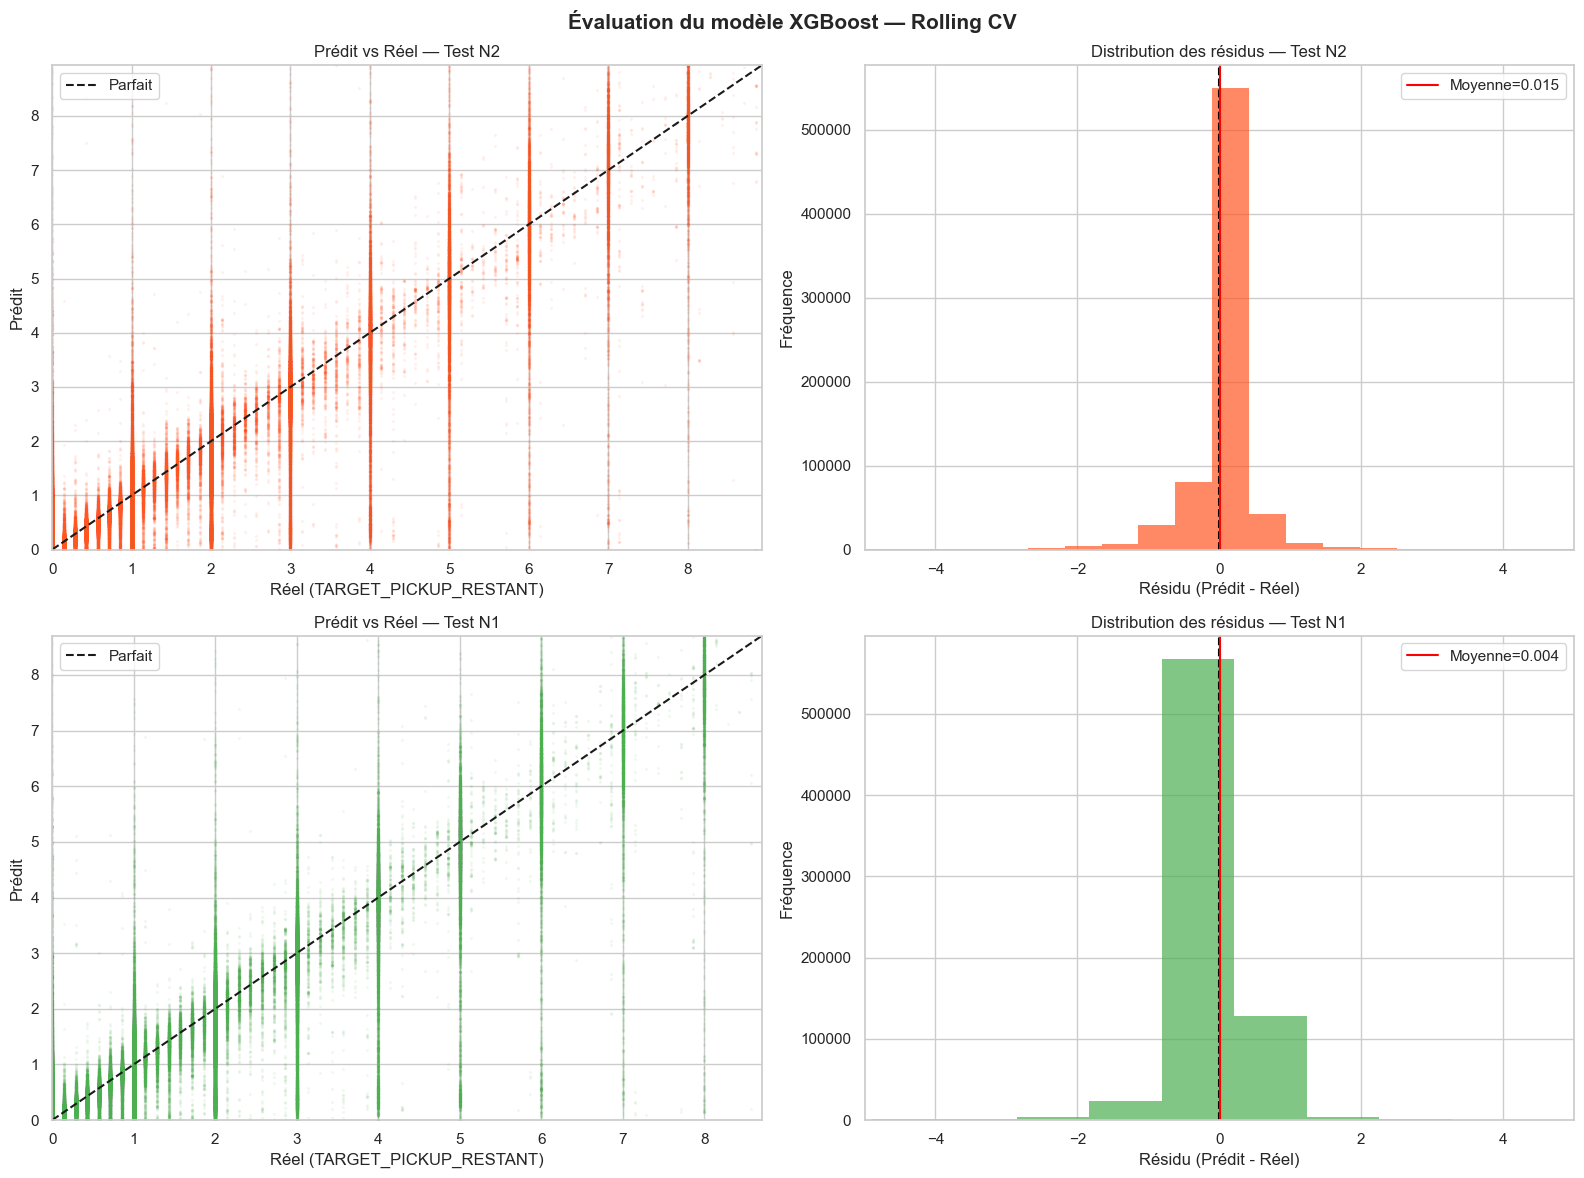

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Évaluation du modèle XGBoost — Rolling CV', fontsize=15, fontweight='bold')

colors = {'N2': '#FF5722', 'N1': '#4CAF50'}

for fold_idx, (test_year, fold_data) in enumerate(all_preds.items()):
    y_true = fold_data['y_true']
    y_pred = fold_data['y_pred']
    color  = colors.get(test_year, '#2196F3')

    # --- 1. Scatter : prédit vs réel ---
    ax = axes[fold_idx, 0]
    max_val = min(np.percentile(y_true, 99), np.percentile(y_pred, 99))
    ax.scatter(y_true, y_pred, alpha=0.05, s=2, color=color)
    ax.plot([0, max_val], [0, max_val], 'k--', lw=1.5, label='Parfait')
    ax.set_xlim(0, max_val)
    ax.set_ylim(0, max_val)
    ax.set_xlabel('Réel (TARGET_PICKUP_RESTANT)')
    ax.set_ylabel('Prédit')
    ax.set_title(f'Prédit vs Réel — Test {test_year}')
    ax.legend()

    # --- 2. Distribution des résidus ---
    ax2 = axes[fold_idx, 1]
    residus = y_pred - y_true
    ax2.hist(residus, bins=100, color=color, alpha=0.7, edgecolor='none')
    ax2.axvline(0, color='black', lw=1.5, linestyle='--')
    ax2.axvline(residus.mean(), color='red', lw=1.5, linestyle='-', label=f'Moyenne={residus.mean():.3f}')
    ax2.set_xlabel('Résidu (Prédit - Réel)')
    ax2.set_ylabel('Fréquence')
    ax2.set_title(f'Distribution des résidus — Test {test_year}')
    ax2.set_xlim(-5, 5)
    ax2.legend()

plt.tight_layout()
plt.show()


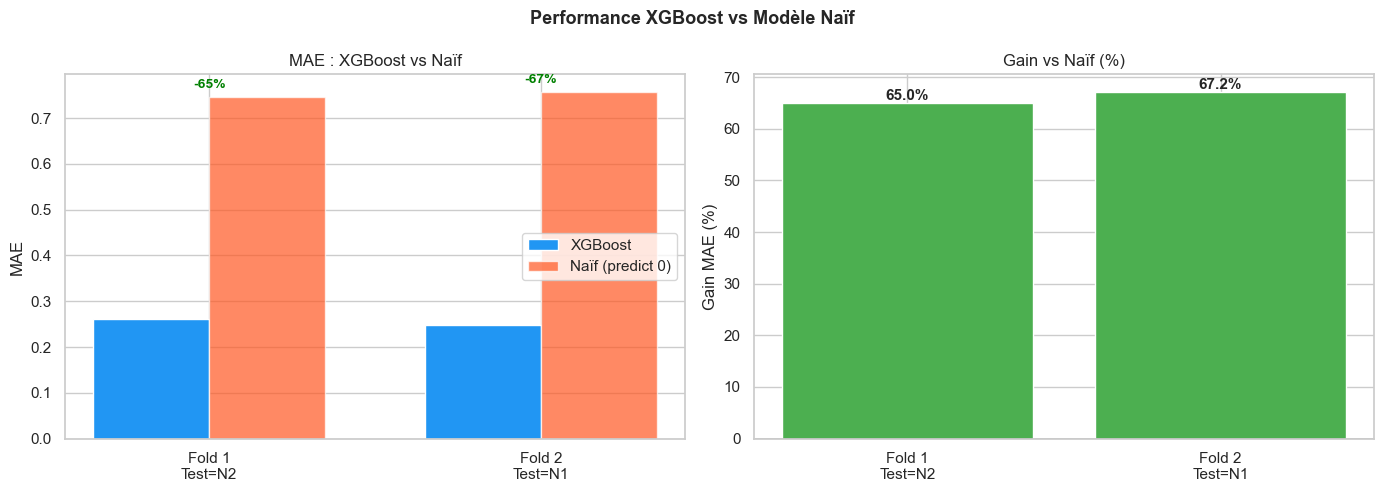

In [19]:
# --- Graphique 3 : MAE vs MAE naïf par fold ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Performance XGBoost vs Modèle Naïf', fontsize=13, fontweight='bold')

x = np.arange(len(cv_results))
width = 0.35

# MAE
axes[0].bar(x - width/2, cv_results['mae'],       width, label='XGBoost', color='#2196F3')
axes[0].bar(x + width/2, cv_results['mae_naive'], width, label='Naïf (predict 0)', color='#FF5722', alpha=0.7)
axes[0].set_xticks(x)
axes[0].set_xticklabels([f'Fold {r["fold"]}\nTest={r["test"]}' for _, r in cv_results.iterrows()])
axes[0].set_ylabel('MAE')
axes[0].set_title('MAE : XGBoost vs Naïf')
axes[0].legend()
for xi, (mae, mae_n) in enumerate(zip(cv_results['mae'], cv_results['mae_naive'])):
    gain = (1 - mae/mae_n)*100
    axes[0].text(xi, max(mae, mae_n) + 0.02, f'-{gain:.0f}%', ha='center', fontsize=10, color='green', fontweight='bold')

# Gain %
axes[1].bar(x, cv_results['gain_mae_pct'], color='#4CAF50')
axes[1].set_xticks(x)
axes[1].set_xticklabels([f'Fold {r["fold"]}\nTest={r["test"]}' for _, r in cv_results.iterrows()])
axes[1].set_ylabel('Gain MAE (%)')
axes[1].set_title('Gain vs Naïf (%)')
axes[1].axhline(0, color='black', lw=1)
for xi, g in enumerate(cv_results['gain_mae_pct']):
    axes[1].text(xi, g + 0.5, f'{g:.1f}%', ha='center', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()


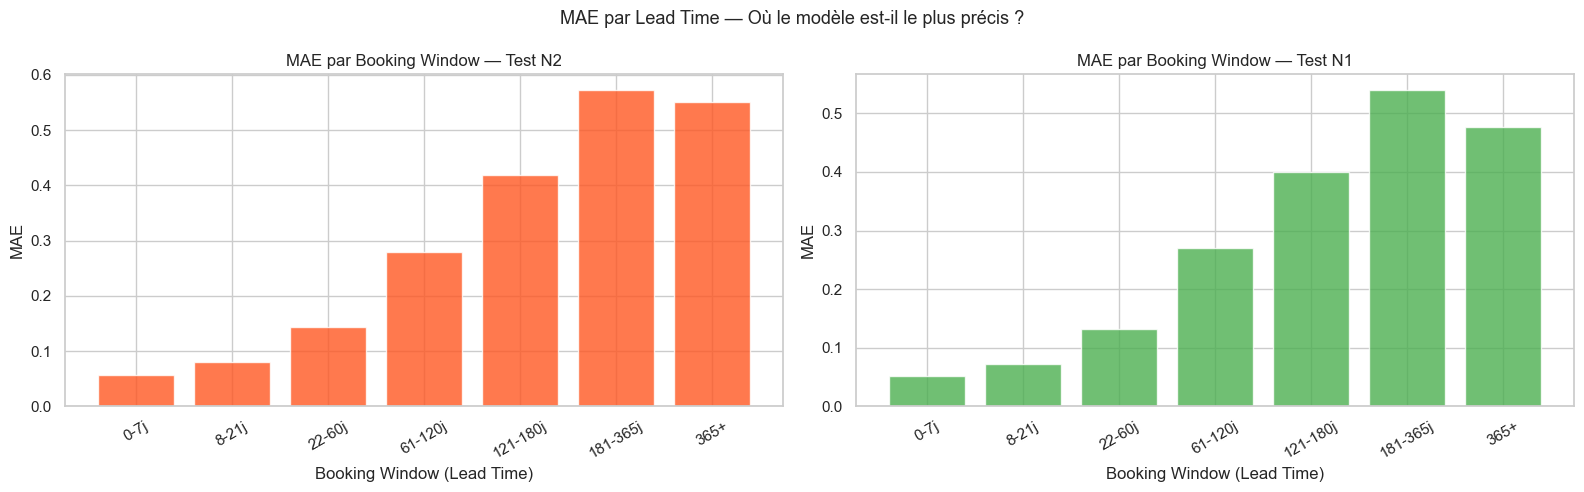

In [20]:
# --- Graphique 4 : MAE par lead time (performance selon horizon) ---
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle('MAE par Lead Time — Où le modèle est-il le plus précis ?', fontsize=13)

for fold_idx, (test_year, fold_data) in enumerate(all_preds.items()):
    y_true = fold_data['y_true']
    y_pred = fold_data['y_pred']
    idx    = fold_data['index']

    lt = long_df.loc[idx, 'LEAD_TIME_JOURS'].values
    df_eval = pd.DataFrame({'y_true': y_true, 'y_pred': y_pred, 'lead_time': lt})

    bins_lt   = [0, 7, 21, 60, 120, 180, 365, 789]
    labels_lt = ['0-7j','8-21j','22-60j','61-120j','121-180j','181-365j','365+']
    df_eval['BW'] = pd.cut(df_eval['lead_time'], bins=bins_lt, labels=labels_lt)

    mae_bw = df_eval.groupby('BW', observed=True).apply(
        lambda g: mean_absolute_error(g['y_true'], g['y_pred'])
    ).reset_index(name='MAE')

    color = colors.get(test_year, '#2196F3')
    axes[fold_idx].bar(mae_bw['BW'].astype(str), mae_bw['MAE'], color=color, alpha=0.8)
    axes[fold_idx].set_title(f'MAE par Booking Window — Test {test_year}')
    axes[fold_idx].set_xlabel('Booking Window (Lead Time)')
    axes[fold_idx].set_ylabel('MAE')
    axes[fold_idx].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()


## 3. Modèle Final (Train = N3 + N2 + N1)

> CV validé → on entraîne le modèle final sur toutes les données historiques disponibles.
> Ce modèle sera utilisé pour prédire sur N (exercice courant).


In [21]:
final_mask = X[year_col].astype(str).isin(['N3', 'N2', 'N1'])
X_final = X.loc[final_mask].drop(columns=[year_col]).copy()
y_final = y.loc[final_mask].copy()

final_model = XGBRegressor(
    n_estimators=2000, max_depth=6, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8,
    tree_method='hist', enable_categorical=True,
    random_state=42, n_jobs=-1
)
final_model.fit(X_final, y_final, verbose=False)
print(f'Modèle final entraîné sur {len(X_final):,} observations (N3+N2+N1)')


Modèle final entraîné sur 2,197,749 observations (N3+N2+N1)


Top 20 features :
VOL_CREAT_CUMUL_HIST_LT61    0.1346
VOL_CREAT_CUMUL_HIST_LT33    0.0879
VOL_CUMUL_HIST               0.0807
VOL_CREAT_CUMUL_HIST_LT89    0.0759
VOL_CUMUL_HIST_LT12          0.0540
VOL_MODIF_CUMUL_HIST         0.0534
VOL_CREAT_CUMUL_HIST_LT131   0.0517
VOL_CUMUL_HIST_LT5           0.0497
VOL_CREAT_CUMUL_HIST_LT19    0.0453
VOL_CREAT_CUMUL_HIST_LT5     0.0440
VOL_CUMUL_HIST_LT19          0.0355
VOL_CREAT_CUMUL_HIST         0.0303
VOL_CUMUL_HIST_LT33          0.0241
VOL_CUMUL_HIST_LT61          0.0236
SEGMENT_DOSSIER              0.0134
VOL_CUMUL_HIST_LT89          0.0121
VOL_NET_HIST                 0.0120
VOL_ANN_CUMUL_HIST           0.0109
VOL_CREAT_CUMUL_HIST_LT12    0.0102
CA_CUMUL_HIST                0.0083


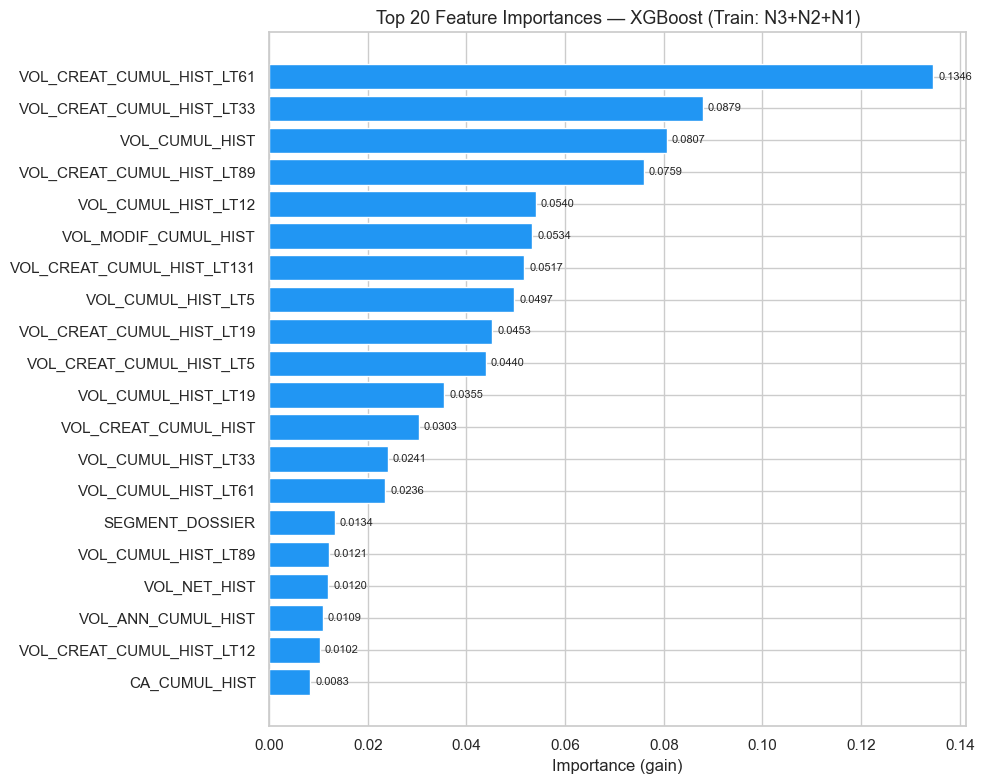

In [22]:
# --- Feature Importance ---
feature_importance = (
    pd.Series(final_model.feature_importances_.astype(float), index=X_final.columns)
    .sort_values(ascending=False)
)

print('Top 20 features :')
print(feature_importance.head(20).to_string())

fig, ax = plt.subplots(figsize=(10, 8))
top20 = feature_importance.head(20)
bars = ax.barh(top20.index[::-1], top20.values[::-1], color='#2196F3')
ax.set_title('Top 20 Feature Importances — XGBoost (Train: N3+N2+N1)', fontsize=13)
ax.set_xlabel('Importance (gain)')
for bar, val in zip(bars, top20.values[::-1]):
    ax.text(bar.get_width() + 0.001, bar.get_y() + bar.get_height()/2,
            f'{val:.4f}', va='center', fontsize=8)
plt.tight_layout()
plt.show()


## 4. Prédiction sur N (Mise en Production)

> Le modèle a été validé sur N2 et N1 — on l'applique maintenant sur l'exercice N.
> `VOL_PREDIT_FINAL = VOL_CUMUL_HIST + TARGET_PICKUP_RESTANT_PREDIT`
>
> ⚠️ Pas de vérité terrain disponible pour N — les graphiques sont donc indicatifs.


In [23]:
mask_N = long_df['ANNEE_MODELE'] == 'N'
X_N = X.loc[mask_N].drop(columns=[year_col]).copy()

preds_N = np.clip(final_model.predict(X_N), 0, None)

predictions_N = long_df.loc[mask_N, [
    'ID_ETABLISSEMENT', 'ID_TYPE_CHAMBRE', 'NB_PERS_CHAMBRE',
    'PARTENAIRE_SEG2', 'DUREE_SEJOUR', 'SEGMENT_DOSSIER',
    'SAISON', 'SEMAINE_SEJOUR', 'DATE_OBSERVATION',
    'LEAD_TIME_JOURS', 'VOL_CUMUL_HIST', 'VOL_FINAL'
]].copy()

predictions_N['TARGET_PICKUP_PREDIT'] = preds_N
predictions_N['VOL_PREDIT_FINAL']     = predictions_N['VOL_CUMUL_HIST'] + preds_N

print(f'Shape prédictions N : {predictions_N.shape}')
print(predictions_N[['LEAD_TIME_JOURS','VOL_CUMUL_HIST','TARGET_PICKUP_PREDIT','VOL_PREDIT_FINAL']].describe())


Shape prédictions N : (732583, 14)
       LEAD_TIME_JOURS  VOL_CUMUL_HIST  TARGET_PICKUP_PREDIT  VOL_PREDIT_FINAL
count      732583.0000     732583.0000           732583.0000       732583.0000
mean           87.5327          0.6731                0.4343            1.1074
std            73.1098          1.9571                1.2925            2.5333
min             5.0000         -2.0000                0.0000           -0.8178
25%            26.0000          0.0000                0.0121            0.0191
50%            68.0000          0.0000                0.0833            0.1657
75%           131.0000          0.8571                0.3035            1.0885
max           789.0000         82.0000               61.7229           84.3008


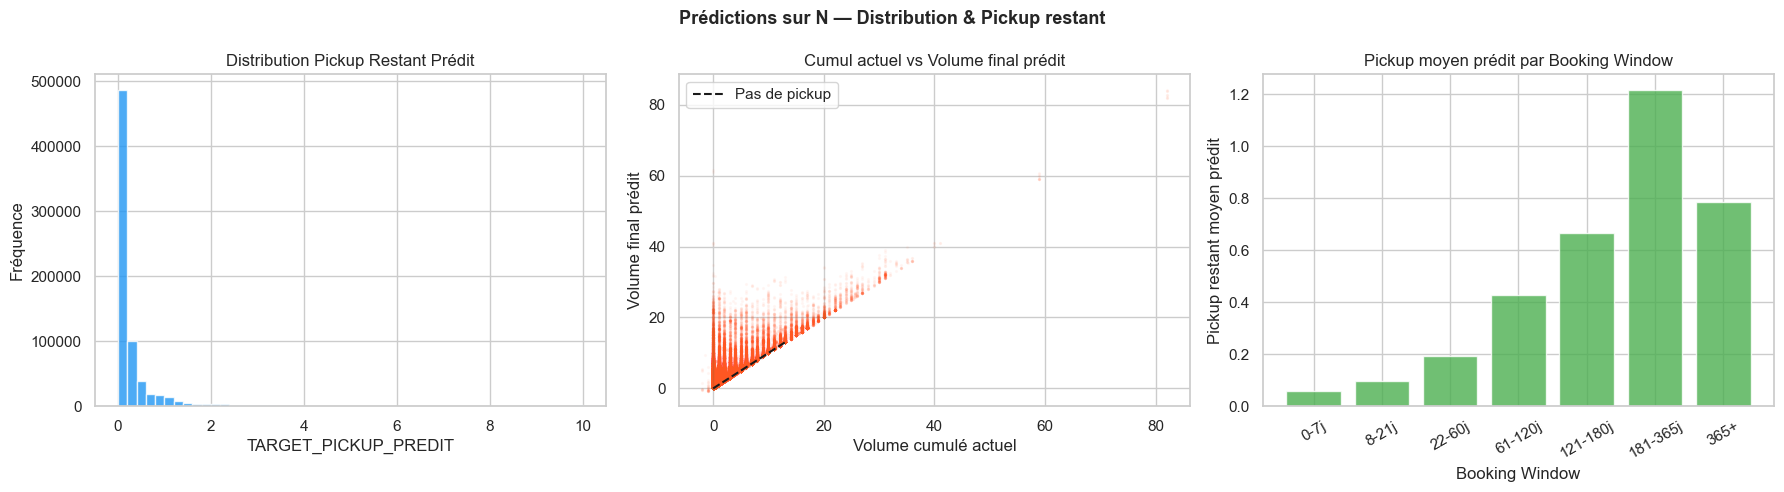

In [24]:
# --- Graphique : Distribution des prédictions N ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Prédictions sur N — Distribution & Pickup restant', fontsize=13, fontweight='bold')

# 1. Distribution TARGET_PICKUP_PREDIT
axes[0].hist(predictions_N['TARGET_PICKUP_PREDIT'].clip(0, 10), bins=50, color='#2196F3', alpha=0.8)
axes[0].set_title('Distribution Pickup Restant Prédit')
axes[0].set_xlabel('TARGET_PICKUP_PREDIT')
axes[0].set_ylabel('Fréquence')

# 2. VOL_CUMUL_HIST vs VOL_PREDIT_FINAL
axes[1].scatter(
    predictions_N['VOL_CUMUL_HIST'],
    predictions_N['VOL_PREDIT_FINAL'],
    alpha=0.03, s=2, color='#FF5722'
)
max_v = predictions_N[['VOL_CUMUL_HIST','VOL_PREDIT_FINAL']].quantile(0.99).max()
axes[1].plot([0, max_v], [0, max_v], 'k--', lw=1.5, label='Pas de pickup')
axes[1].set_xlabel('Volume cumulé actuel')
axes[1].set_ylabel('Volume final prédit')
axes[1].set_title('Cumul actuel vs Volume final prédit')
axes[1].legend()

# 3. Pickup prédit par Lead Time
lt_bins   = [0, 7, 21, 60, 120, 180, 365, 789]
lt_labels = ['0-7j','8-21j','22-60j','61-120j','121-180j','181-365j','365+']
predictions_N['BW'] = pd.cut(predictions_N['LEAD_TIME_JOURS'], bins=lt_bins, labels=lt_labels)
pickup_bw = predictions_N.groupby('BW', observed=True)['TARGET_PICKUP_PREDIT'].mean()
axes[2].bar(pickup_bw.index.astype(str), pickup_bw.values, color='#4CAF50', alpha=0.8)
axes[2].set_title('Pickup moyen prédit par Booking Window')
axes[2].set_xlabel('Booking Window')
axes[2].set_ylabel('Pickup restant moyen prédit')
axes[2].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()


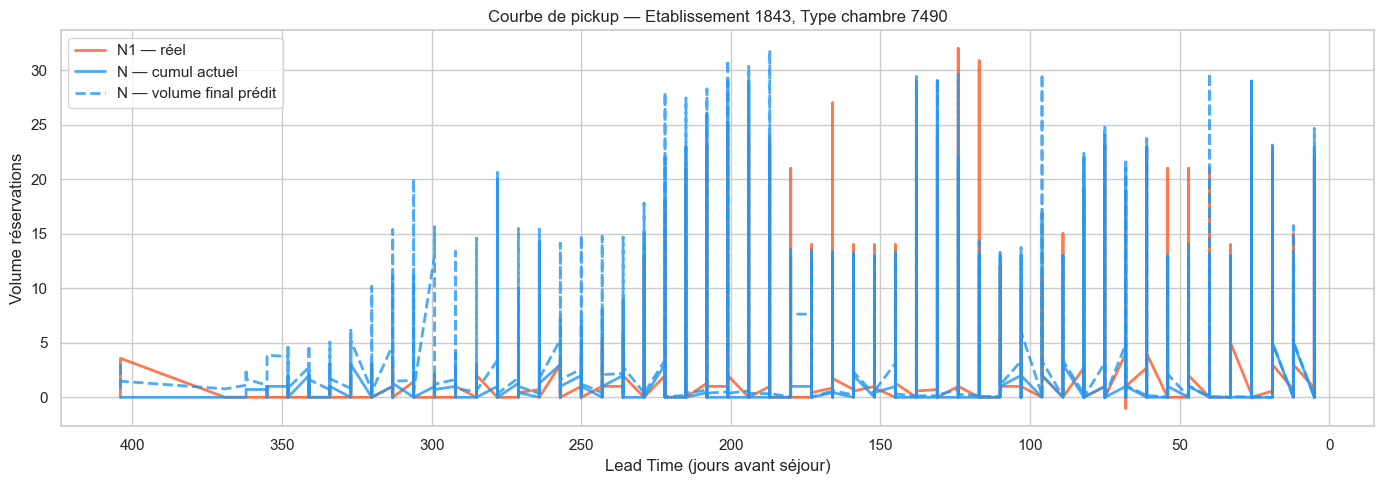

In [25]:
# --- Courbe de pickup prédite vs historique pour un établissement ---
# Comparer la trajectoire N prédite avec N1 réelle

etab_ex = predictions_N['ID_ETABLISSEMENT'].value_counts().index[0]
type_ex = predictions_N.loc[predictions_N['ID_ETABLISSEMENT']==etab_ex, 'ID_TYPE_CHAMBRE'].value_counts().index[0]

mask_ex_N  = (predictions_N['ID_ETABLISSEMENT']==etab_ex) & (predictions_N['ID_TYPE_CHAMBRE']==type_ex)
mask_ex_N1 = (
    (long_df['ID_ETABLISSEMENT']==etab_ex) &
    (long_df['ID_TYPE_CHAMBRE']==type_ex) &
    (long_df['ANNEE_MODELE']=='N1')
)

ex_N  = predictions_N[mask_ex_N].sort_values('LEAD_TIME_JOURS', ascending=False)
ex_N1 = long_df[mask_ex_N1].sort_values('LEAD_TIME_JOURS', ascending=False)

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(ex_N1['LEAD_TIME_JOURS'], ex_N1['VOL_CUMUL_HIST'],
        color='#FF5722', lw=2, label='N1 — réel', alpha=0.8)
ax.plot(ex_N['LEAD_TIME_JOURS'],  ex_N['VOL_CUMUL_HIST'],
        color='#2196F3', lw=2, label='N — cumul actuel', alpha=0.8)
ax.plot(ex_N['LEAD_TIME_JOURS'],  ex_N['VOL_PREDIT_FINAL'],
        color='#2196F3', lw=2, linestyle='--', label='N — volume final prédit', alpha=0.8)
ax.set_xlabel('Lead Time (jours avant séjour)')
ax.set_ylabel('Volume réservations')
ax.set_title(f'Courbe de pickup — Etablissement {etab_ex}, Type chambre {type_ex}')
ax.invert_xaxis()
ax.legend()
plt.tight_layout()
plt.show()


In [28]:
# Export prédictions N
predictions_N.to_csv('predictions_N_xgboost.csv', index=False)
print(f'Prédictions exportées : predictions_N_xgboost.csv')
print(f'Shape : {predictions_N.shape}')
predictions_N.head(10)


Prédictions exportées : predictions_N_xgboost.csv
Shape : (732583, 15)


,ID_ETABLISSEMENT,ID_TYPE_CHAMBRE,NB_PERS_CHAMBRE,PARTENAIRE_SEG2,DUREE_SEJOUR,SEGMENT_DOSSIER,SAISON,SEMAINE_SEJOUR,DATE_OBSERVATION,LEAD_TIME_JOURS,VOL_CUMUL_HIST,VOL_FINAL,TARGET_PICKUP_PREDIT,VOL_PREDIT_FINAL,BW
0,1,9,6,CSE Allotement,14n,Allotement,Automne,2025-09-27,2025-09-15,12,0.0000,0.0000,0.0724,0.0724,8-21j
1,1,9,6,CSE Allotement,14n,Allotement,Automne,2026-09-05,2026-06-08,89,0.0000,0.0000,0.2499,0.2499,61-120j
2,1,9,6,CSE Allotement,14n,Allotement,Automne,2026-09-05,2026-08-17,19,0.0000,0.0000,0.0894,0.0894,8-21j
3,1,9,6,CSE Allotement,14n,Allotement,Automne,2026-09-12,2026-06-08,96,0.0000,0.0000,0.2904,0.2904,61-120j
4,1,9,6,CSE Allotement,14n,Allotement,Automne,2026-09-12,2026-08-17,26,0.0000,0.0000,0.1073,0.1073,22-60j
5,1,9,6,CSE Allotement,14n,Allotement,Automne,2026-09-19,2026-06-08,103,0.0000,0.0000,0.3085,0.3085,61-120j
6,1,9,6,CSE Allotement,14n,Allotement,Automne,2026-09-19,2026-09-14,5,0.0000,0.0000,0.0929,0.0929,0-7j
7,1,9,6,CSE Allotement,14n,Allotement,Automne,2026-09-26,2026-09-14,12,0.0000,0.0000,0.0724,0.0724,8-21j
8,1,9,6,TO Etranger,14n,Allotement,Automne,2025-09-27,2025-09-15,12,0.0000,0.0000,0.0000,0.0000,8-21j
9,1,9,6,TO Etranger,14n,Allotement,Automne,2025-10-11,2025-04-21,173,0.0000,0.0000,0.2123,0.2123,121-180j


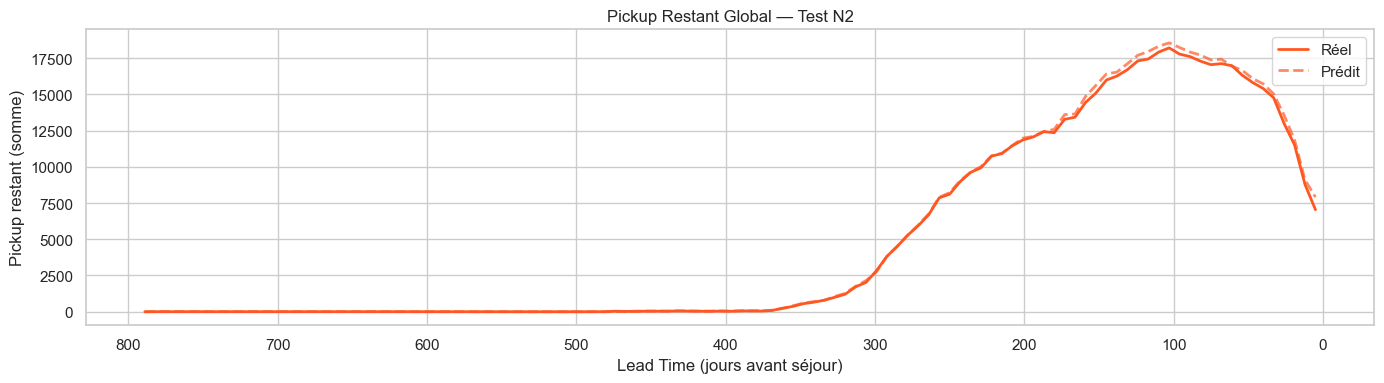

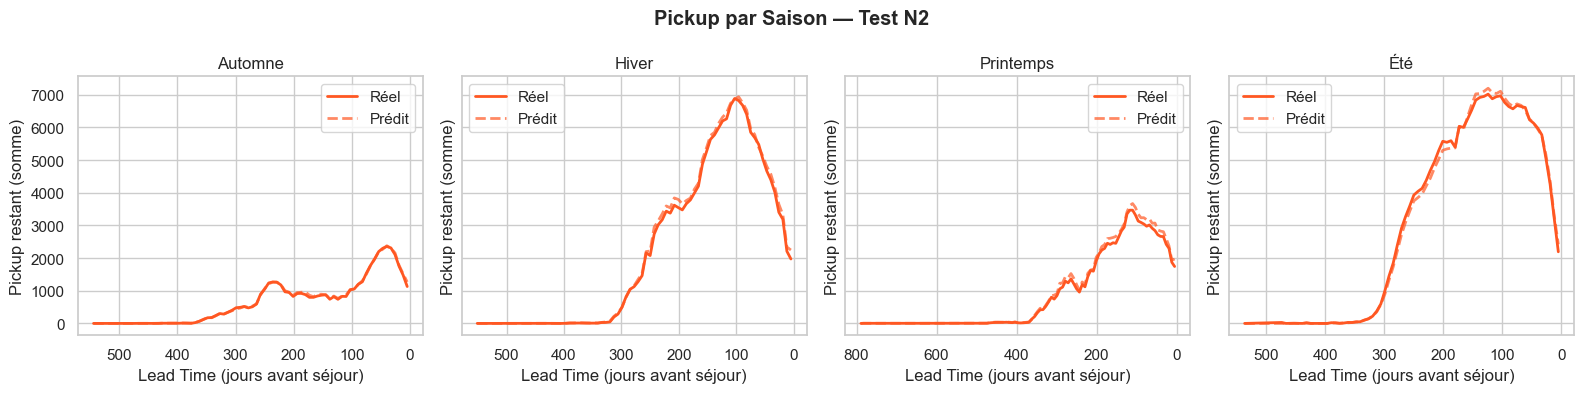

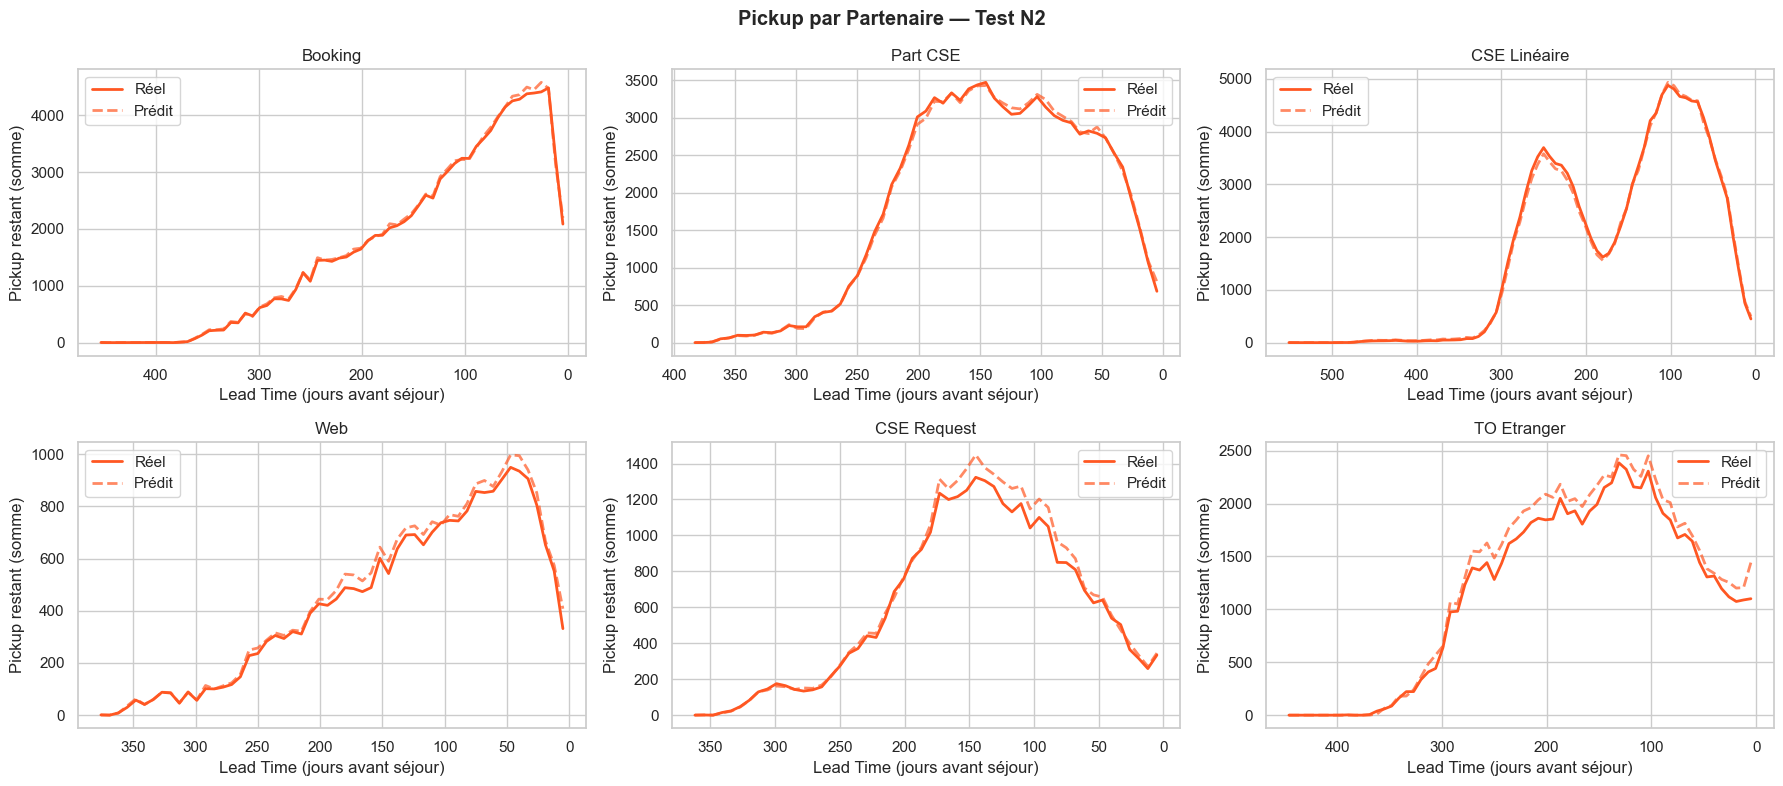

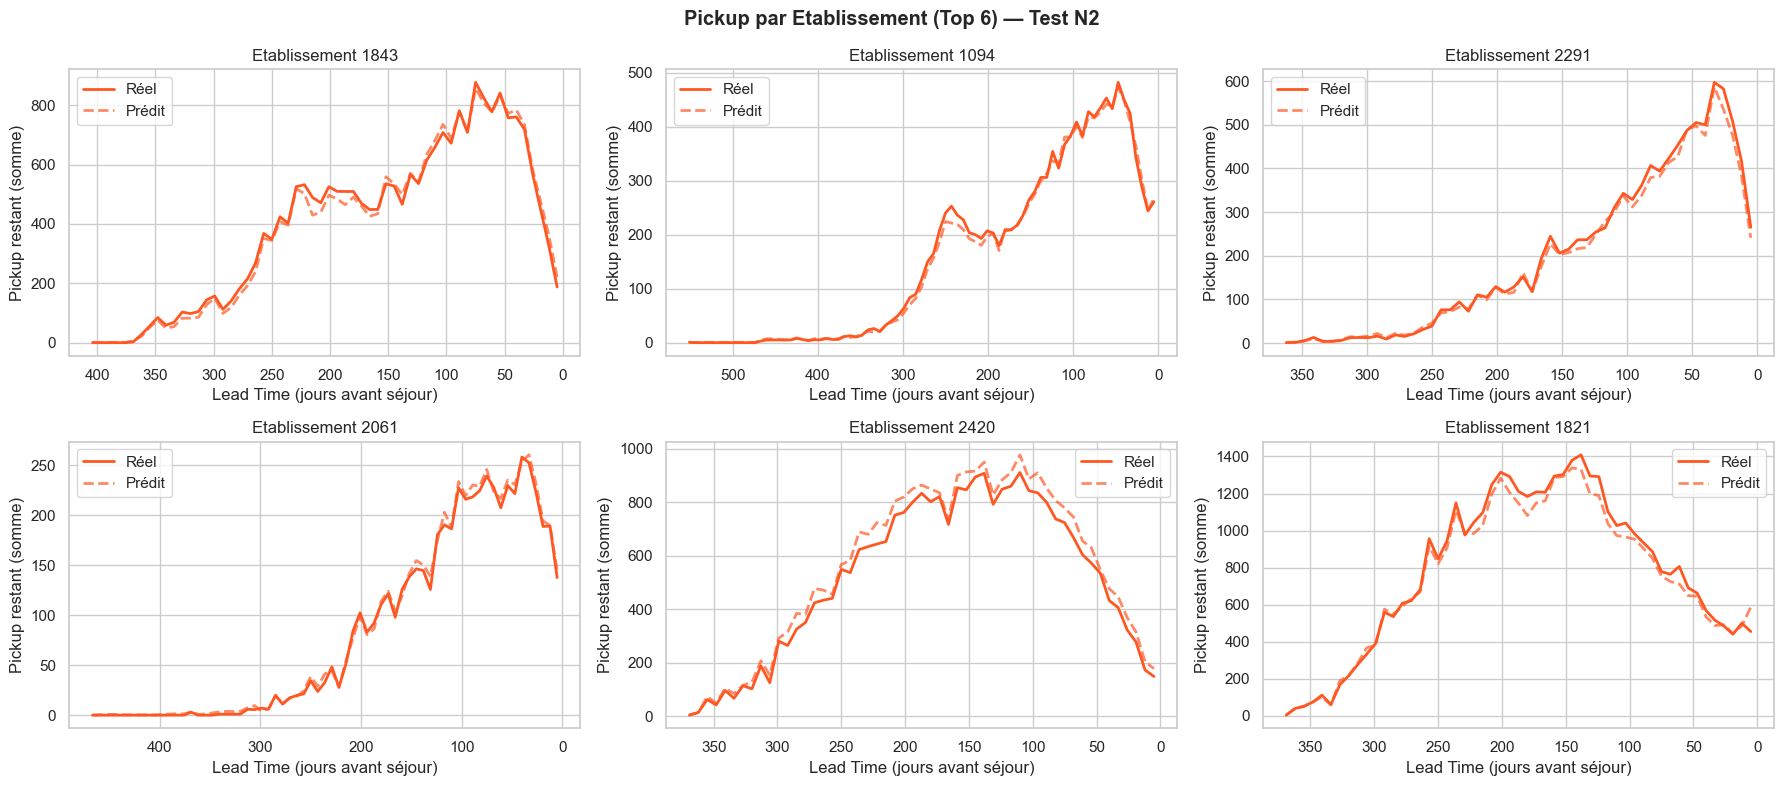

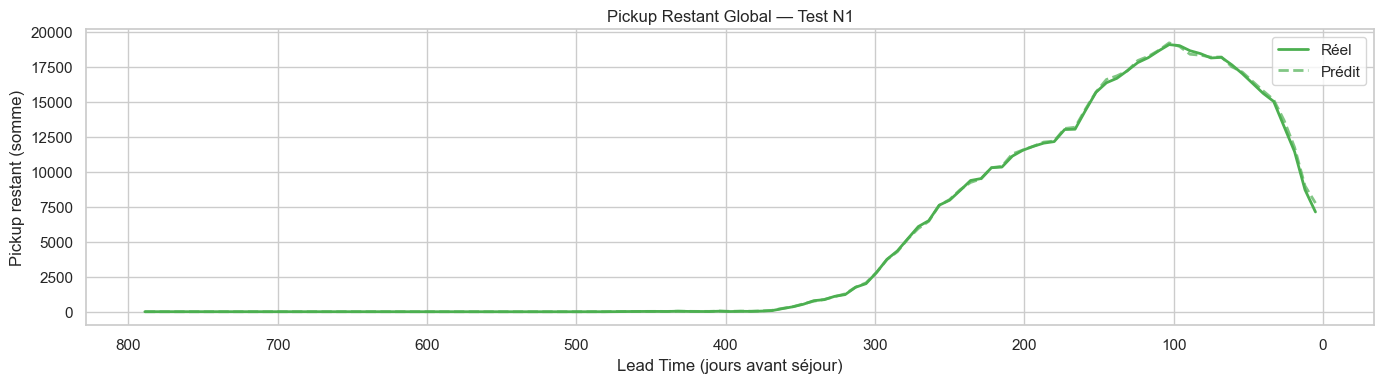

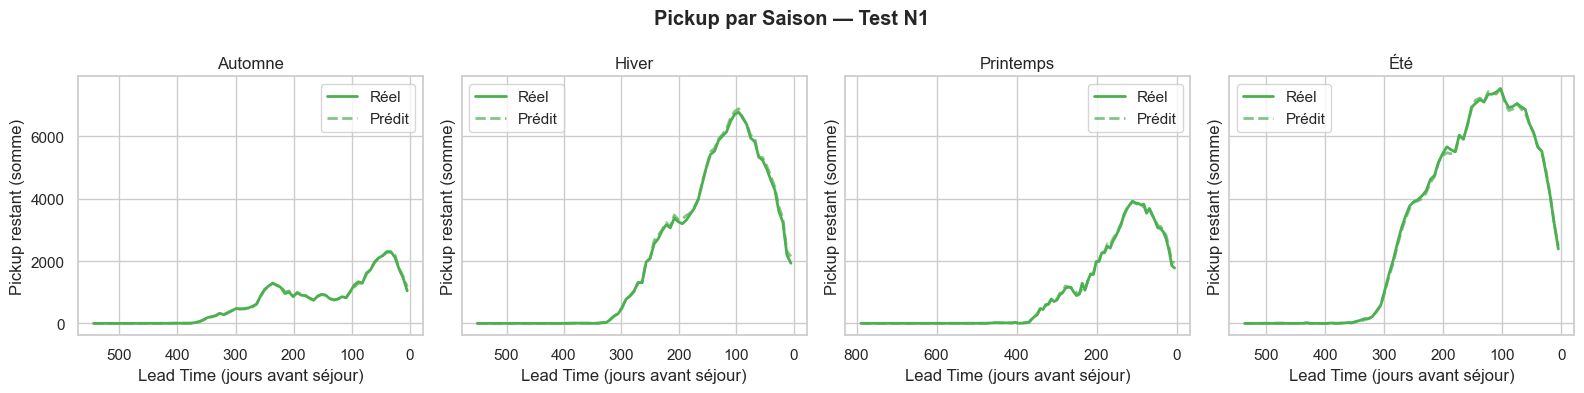

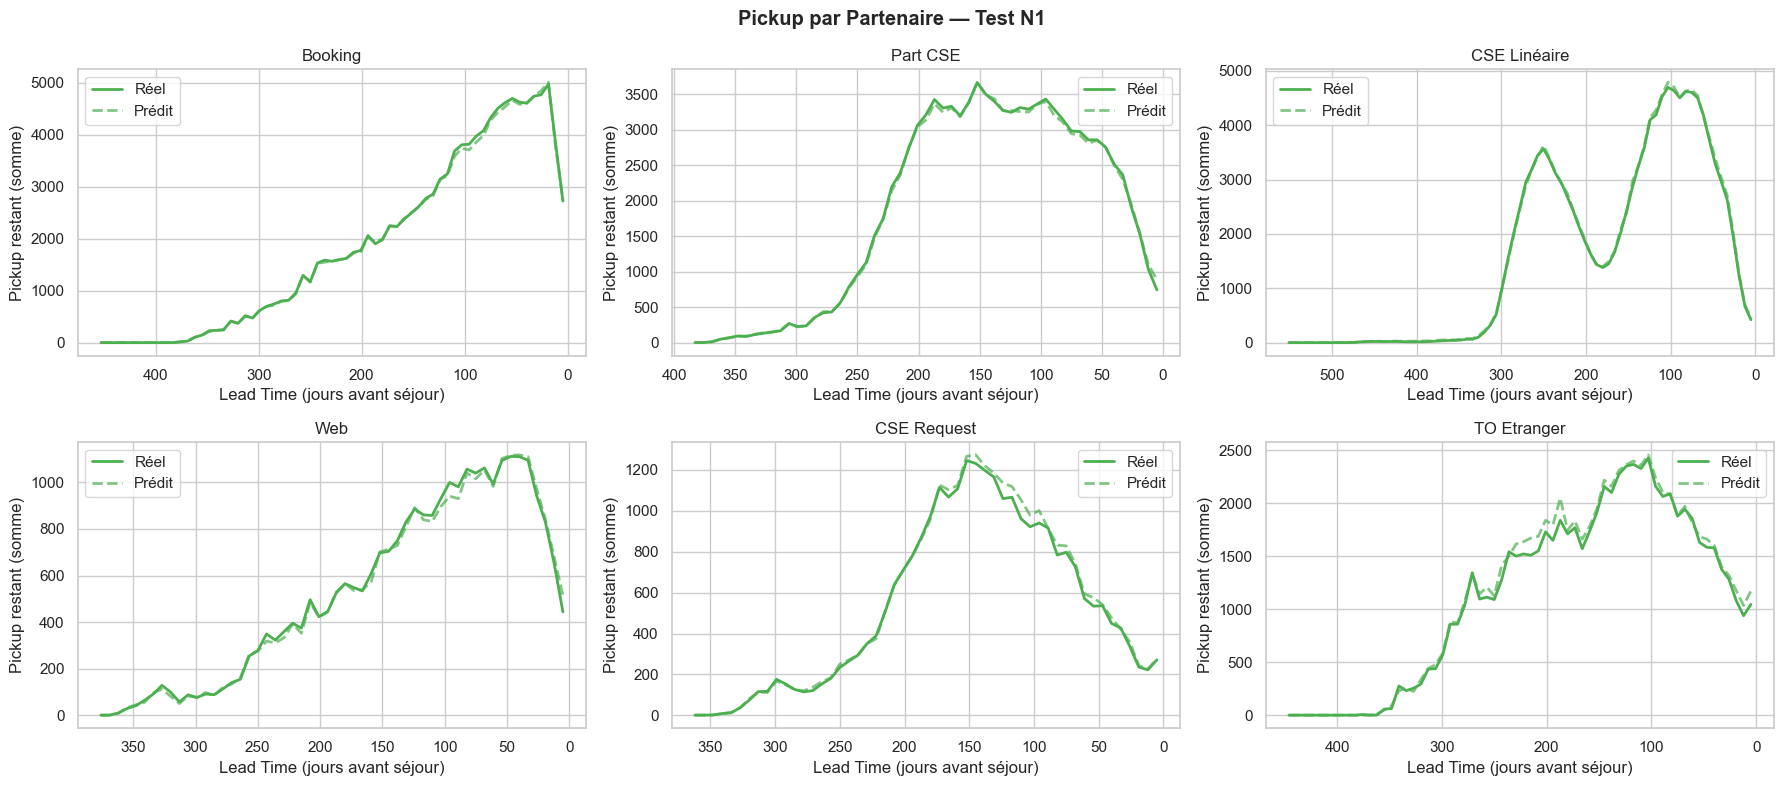

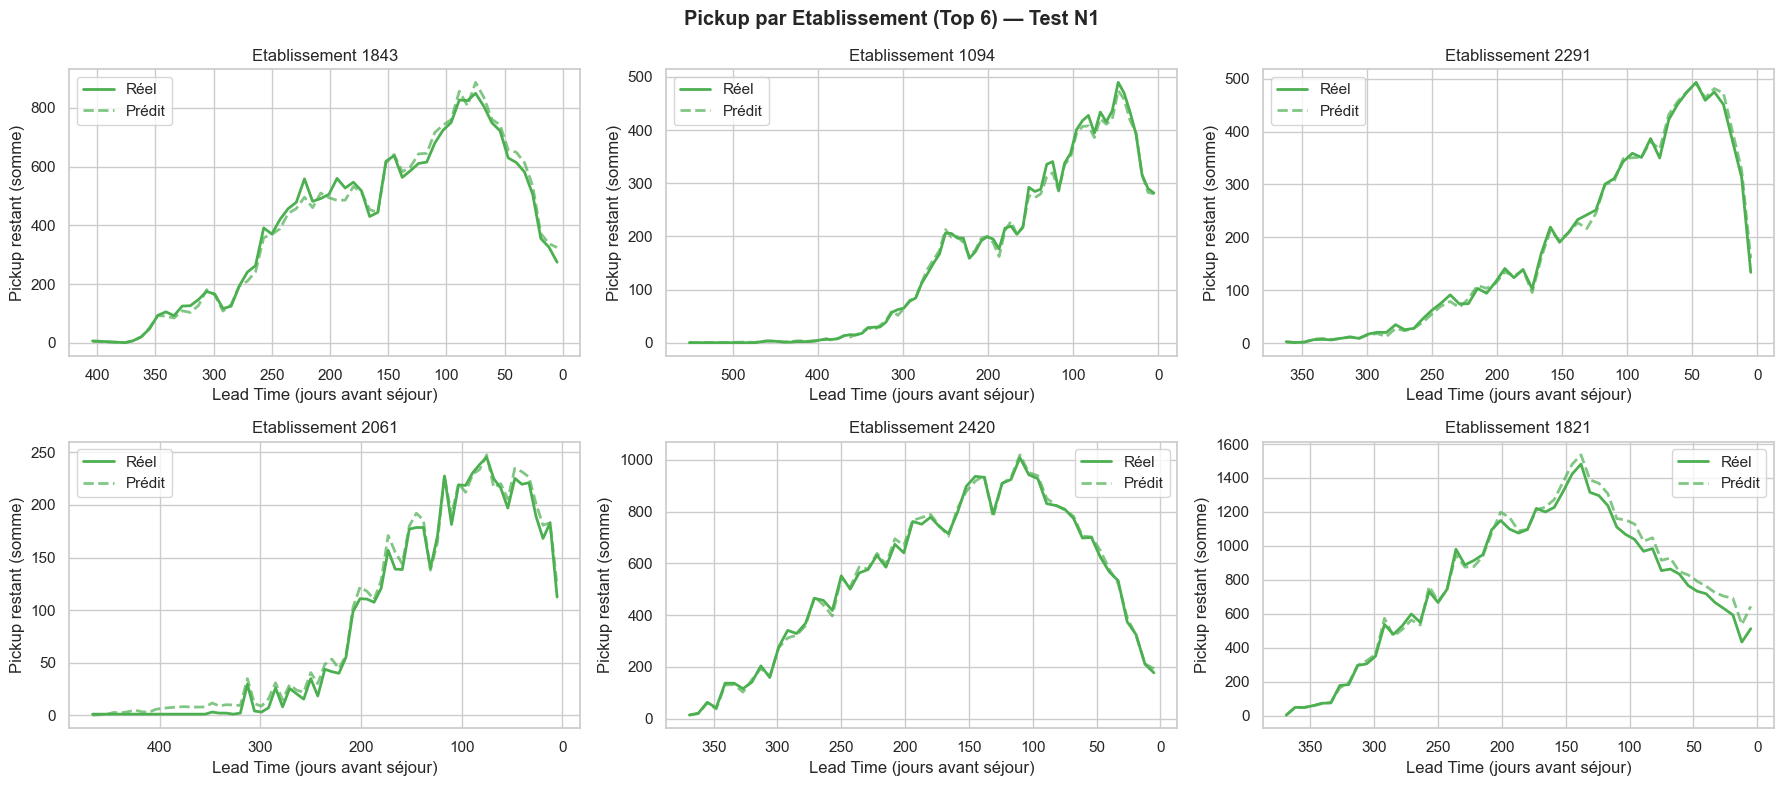

In [29]:
# ============================================================
# Courbes de pickup — Réel vs Prédit
# Niveau : Global, Etablissement, Saison, Partenaire
# ============================================================

def plot_pickup_curve(df_eval, group_col=None, group_val=None, ax=None, title=None, color='#2196F3'):
    """Tracer la courbe de pickup réel vs prédit par lead time"""
    if group_col and group_val:
        df = df_eval[df_eval[group_col] == group_val].copy()
    else:
        df = df_eval.copy()

    # Agréger par lead time
    curve = df.groupby('LEAD_TIME').agg(
        PICKUP_REEL  =('PICKUP_REEL',   'sum'),
        PICKUP_PREDIT=('PICKUP_PREDIT', 'sum')
    ).reset_index().sort_values('LEAD_TIME', ascending=False)

    if ax is None:
        fig, ax = plt.subplots(figsize=(12, 4))

    ax.plot(curve['LEAD_TIME'], curve['PICKUP_REEL'],
            color=color, lw=2, label='Réel')
    ax.plot(curve['LEAD_TIME'], curve['PICKUP_PREDIT'],
            color=color, lw=2, linestyle='--', alpha=0.7, label='Prédit')
    ax.set_xlabel('Lead Time (jours avant séjour)')
    ax.set_ylabel('Pickup restant (somme)')
    ax.set_title(title or 'Courbe de pickup')
    ax.invert_xaxis()
    ax.legend()

# ============================================================
# Construire df_eval pour chaque fold
# ============================================================
for test_year, fold_data in all_preds.items():
    y_true = fold_data['y_true']
    y_pred = fold_data['y_pred']
    idx    = fold_data['index']

    df_eval = pd.DataFrame({
        'LEAD_TIME'        : long_df.loc[idx, 'LEAD_TIME_JOURS'].values,
        'SEMAINE_SEJOUR'   : long_df.loc[idx, 'SEMAINE_SEJOUR'].values,
        'ID_ETABLISSEMENT' : long_df.loc[idx, 'ID_ETABLISSEMENT'].values,
        'SAISON'           : long_df.loc[idx, 'SAISON'].values,
        'PARTENAIRE_SEG2'  : long_df.loc[idx, 'PARTENAIRE_SEG2'].values,
        'PICKUP_REEL'      : y_true,
        'PICKUP_PREDIT'    : y_pred,
    })

    color = '#FF5722' if test_year == 'N2' else '#4CAF50'

    # ── 1. GLOBAL ──────────────────────────────────────────
    fig, ax = plt.subplots(figsize=(14, 4))
    plot_pickup_curve(df_eval, ax=ax, color=color,
                      title=f'Pickup Restant Global — Test {test_year}')
    plt.tight_layout()
    plt.show()

    # ── 2. PAR SAISON ──────────────────────────────────────
    saisons = df_eval['SAISON'].dropna().unique()
    fig, axes = plt.subplots(1, len(saisons), figsize=(16, 4), sharey=True)
    fig.suptitle(f'Pickup par Saison — Test {test_year}', fontweight='bold')
    for i, saison in enumerate(sorted(saisons)):
        plot_pickup_curve(df_eval, 'SAISON', saison,
                          ax=axes[i], color=color, title=saison)
    plt.tight_layout()
    plt.show()

    # ── 3. PAR PARTENAIRE ──────────────────────────────────
    partenaires = df_eval['PARTENAIRE_SEG2'].value_counts().head(6).index
    fig, axes = plt.subplots(2, 3, figsize=(18, 8))
    fig.suptitle(f'Pickup par Partenaire — Test {test_year}', fontweight='bold')
    for i, part in enumerate(partenaires):
        ax = axes[i//3, i%3]
        plot_pickup_curve(df_eval, 'PARTENAIRE_SEG2', part,
                          ax=ax, color=color, title=part)
    plt.tight_layout()
    plt.show()

    # ── 4. PAR ETABLISSEMENT (top 6) ───────────────────────
    top_etabs = df_eval['ID_ETABLISSEMENT'].value_counts().head(6).index
    fig, axes = plt.subplots(2, 3, figsize=(18, 8))
    fig.suptitle(f'Pickup par Etablissement (Top 6) — Test {test_year}', fontweight='bold')
    for i, etab in enumerate(top_etabs):
        ax = axes[i//3, i%3]
        plot_pickup_curve(df_eval, 'ID_ETABLISSEMENT', etab,
                          ax=ax, color=color, title=f'Etablissement {etab}')
    plt.tight_layout()
    plt.show()

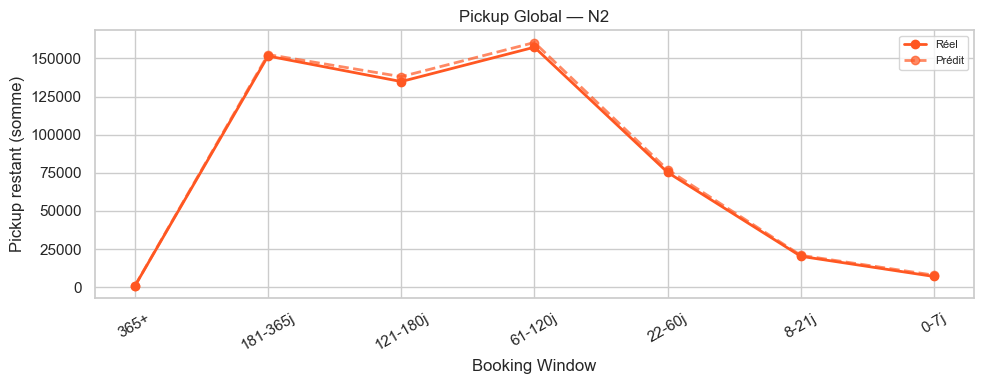

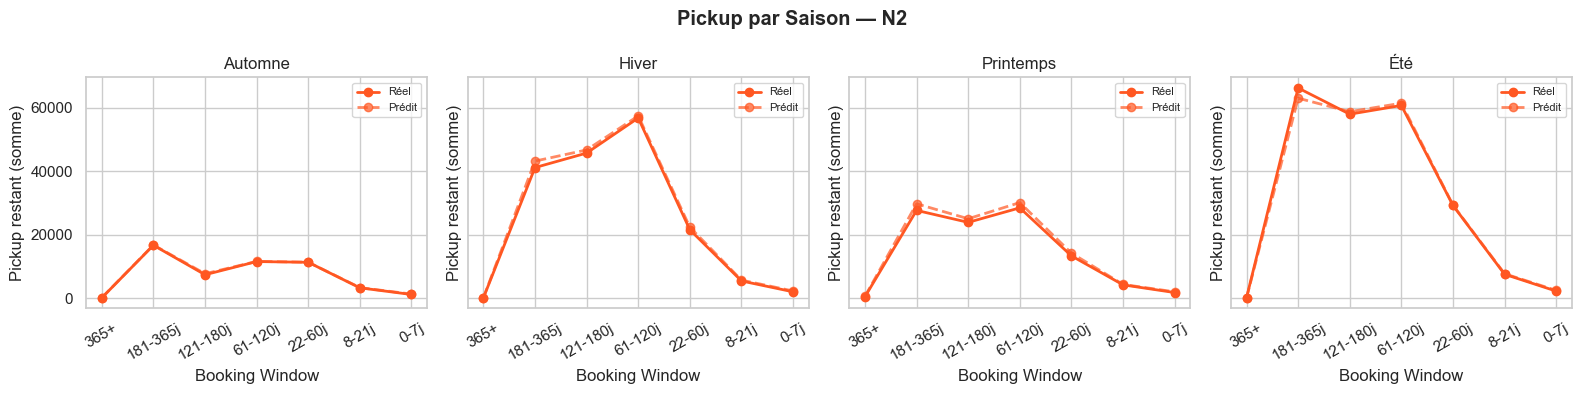

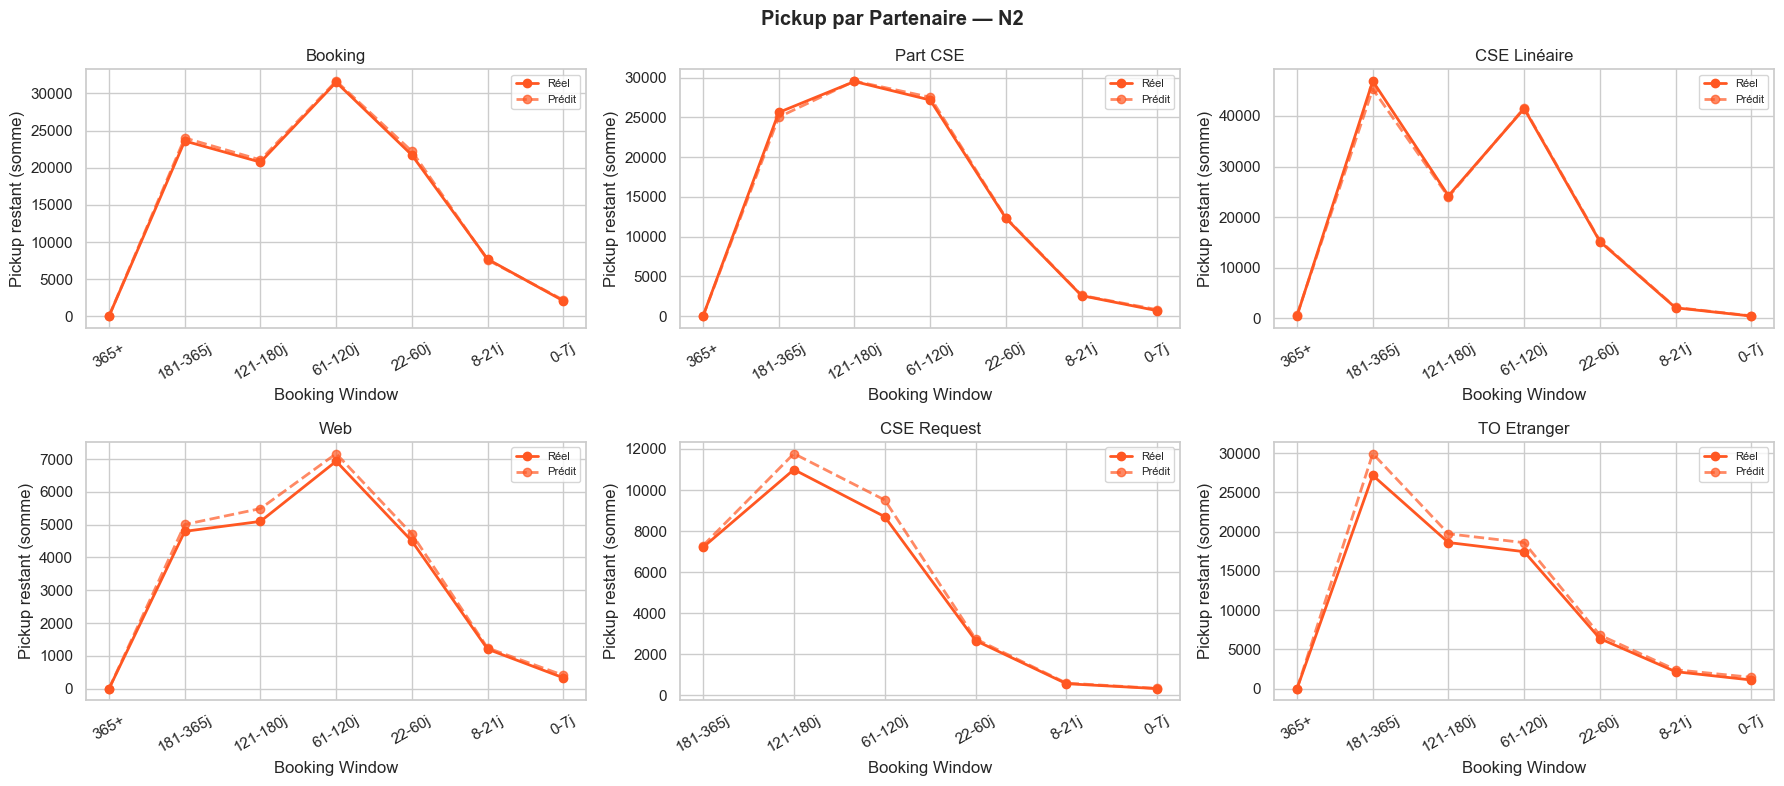

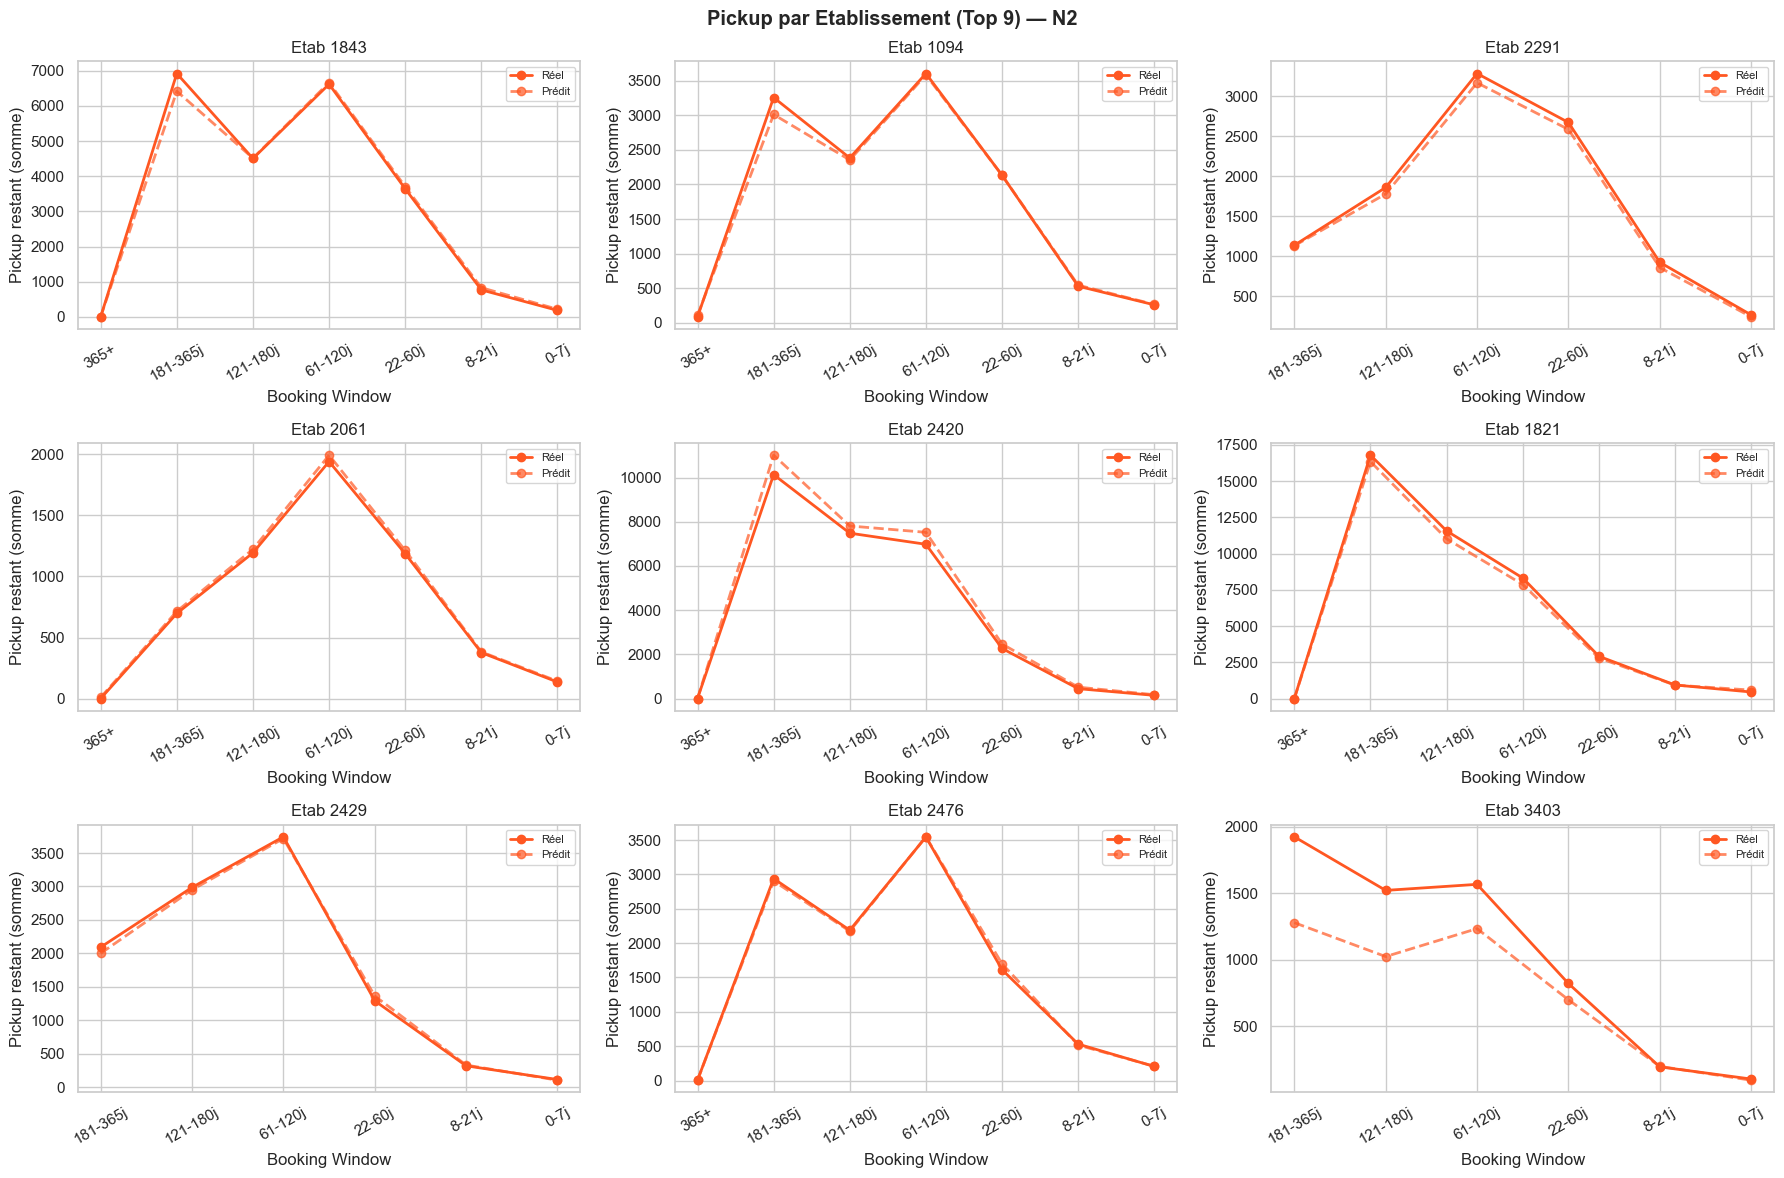

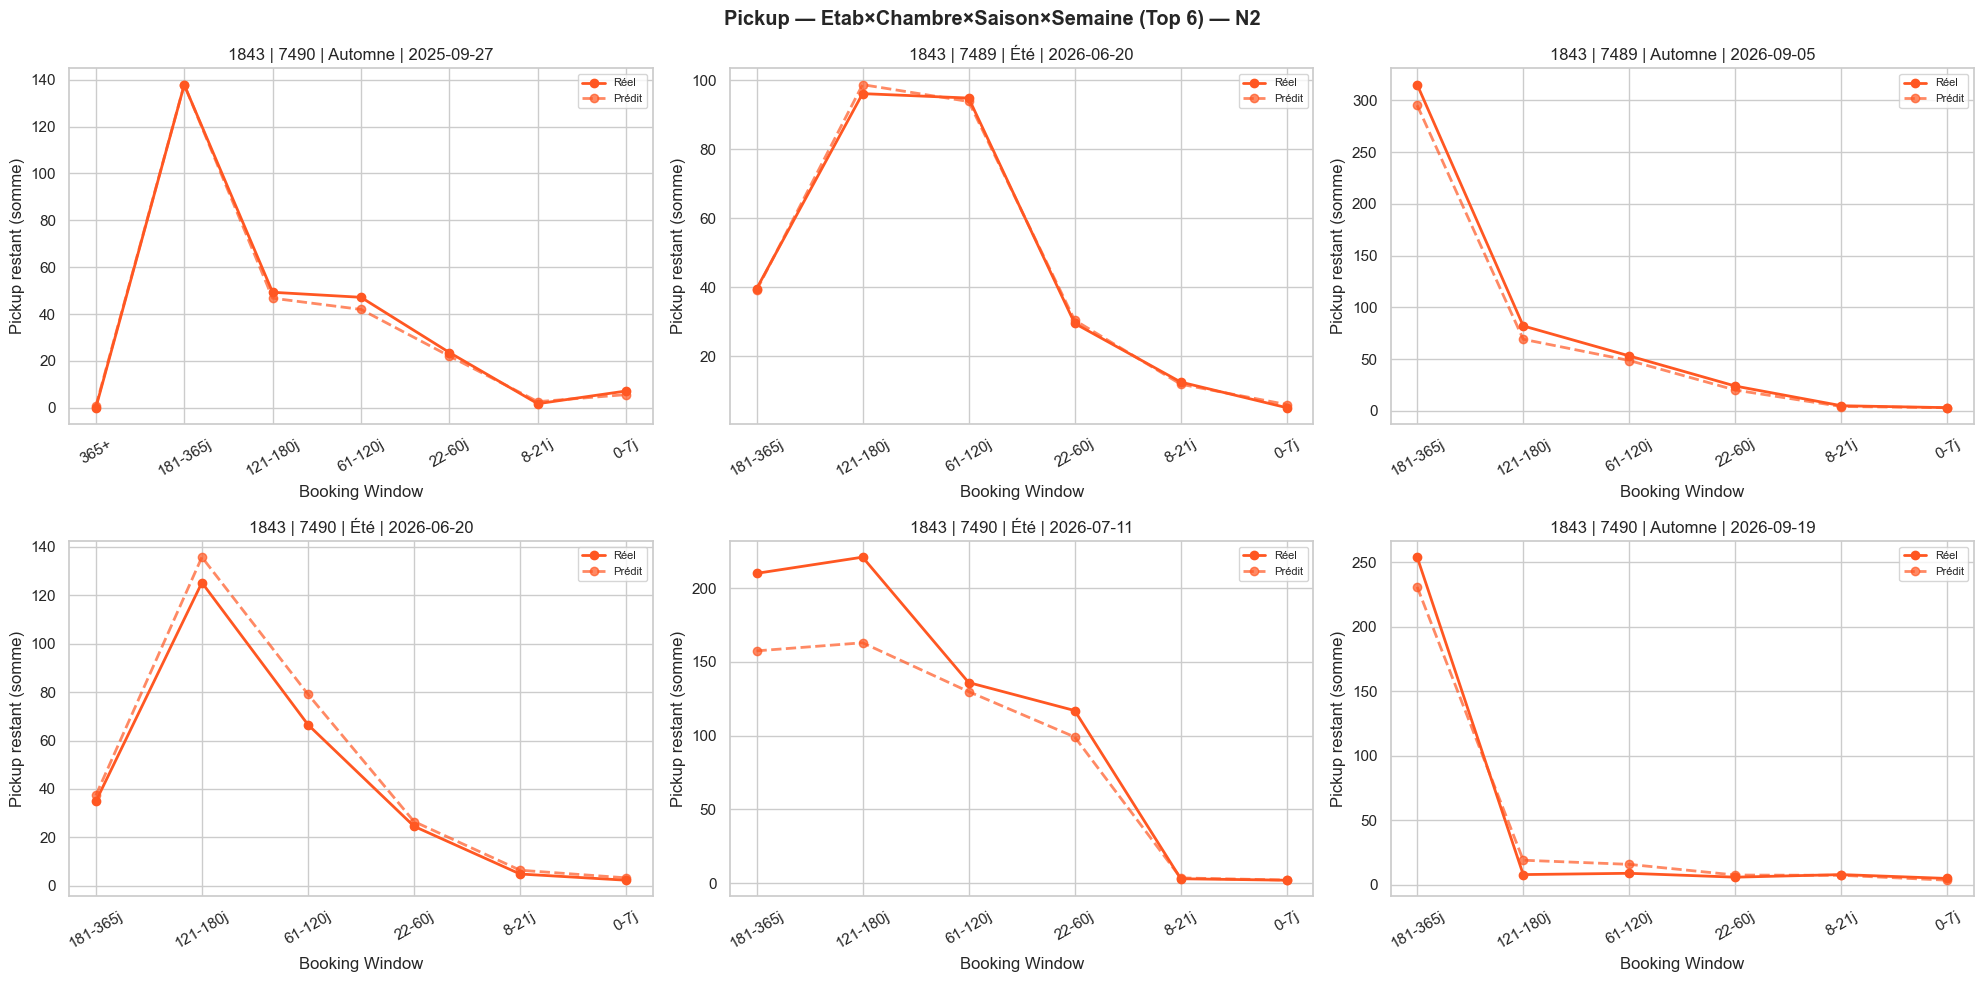

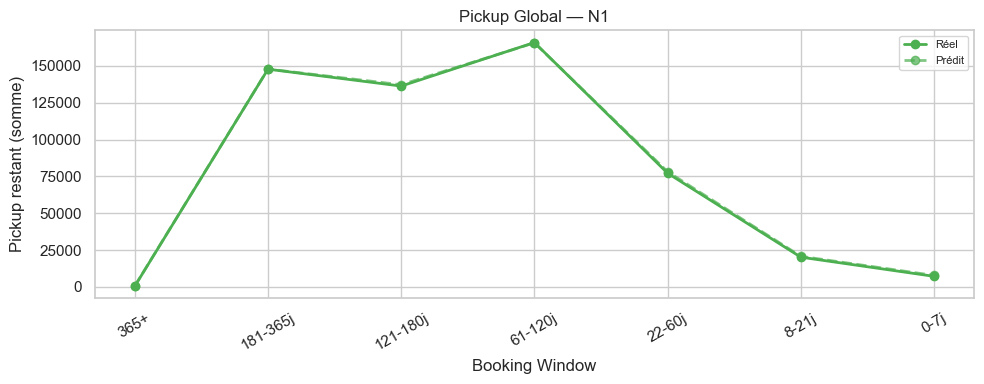

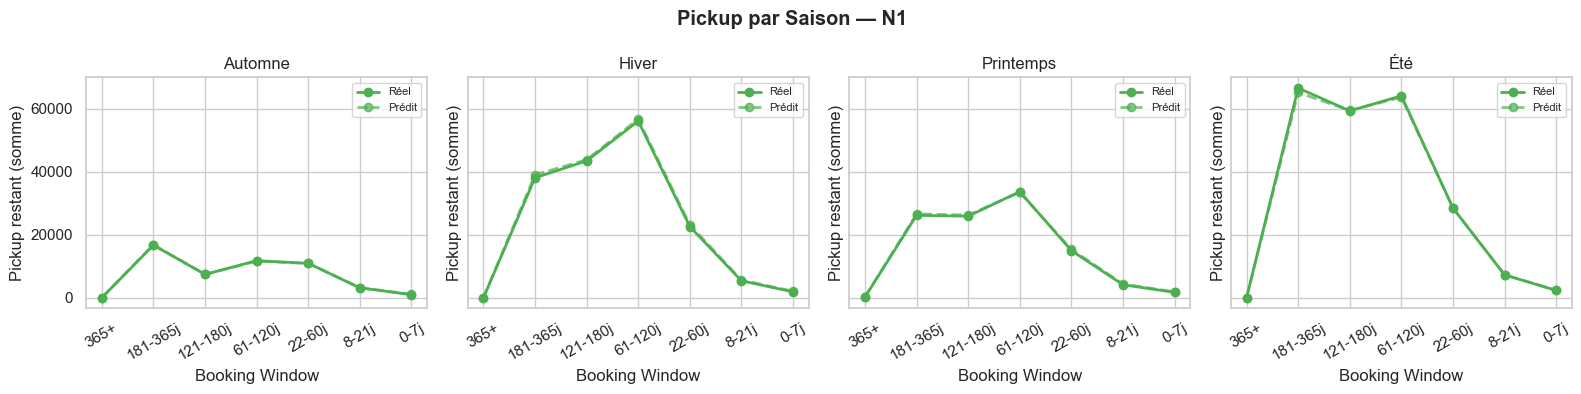

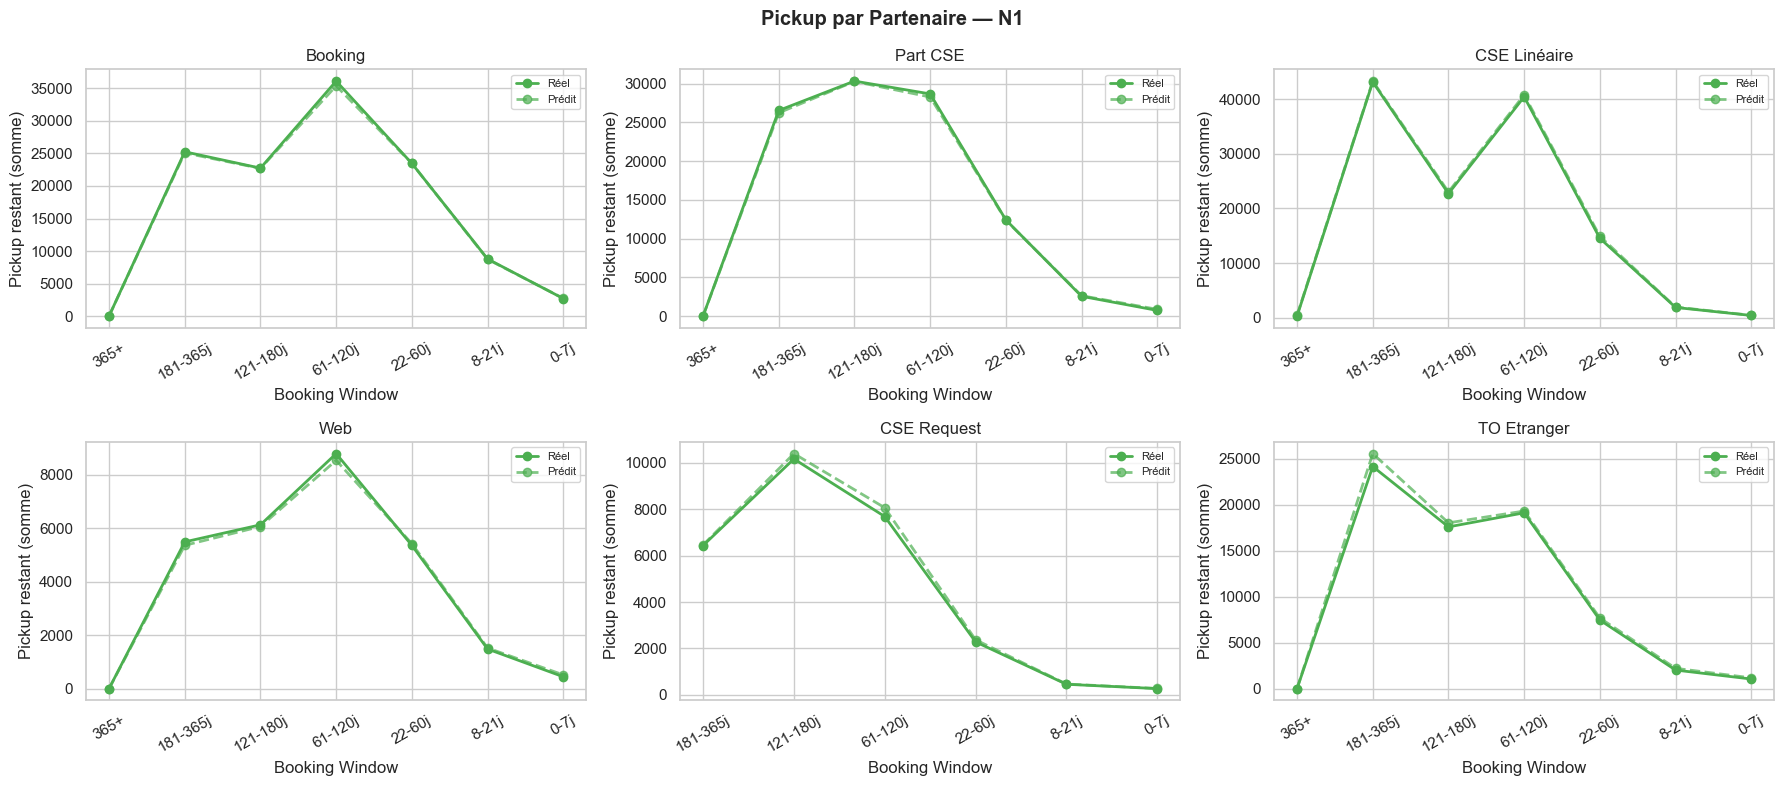

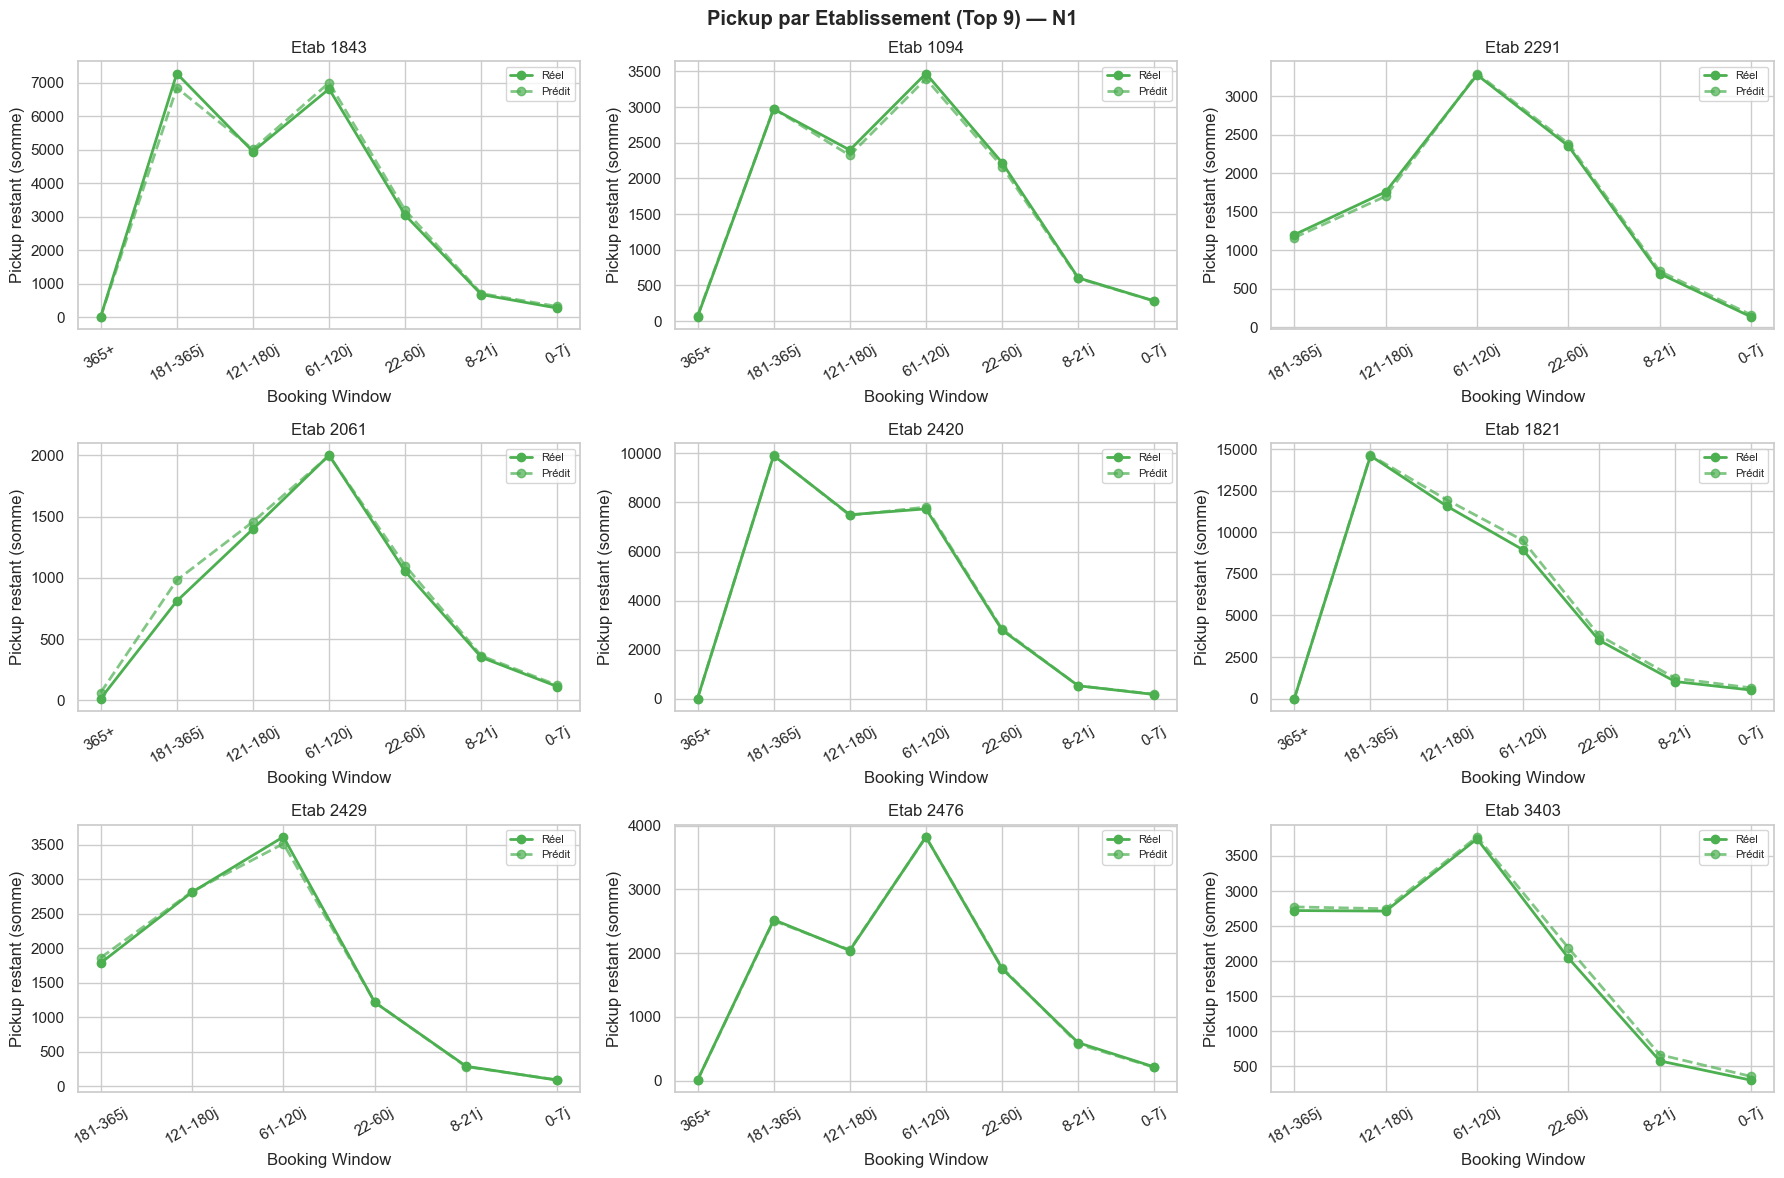

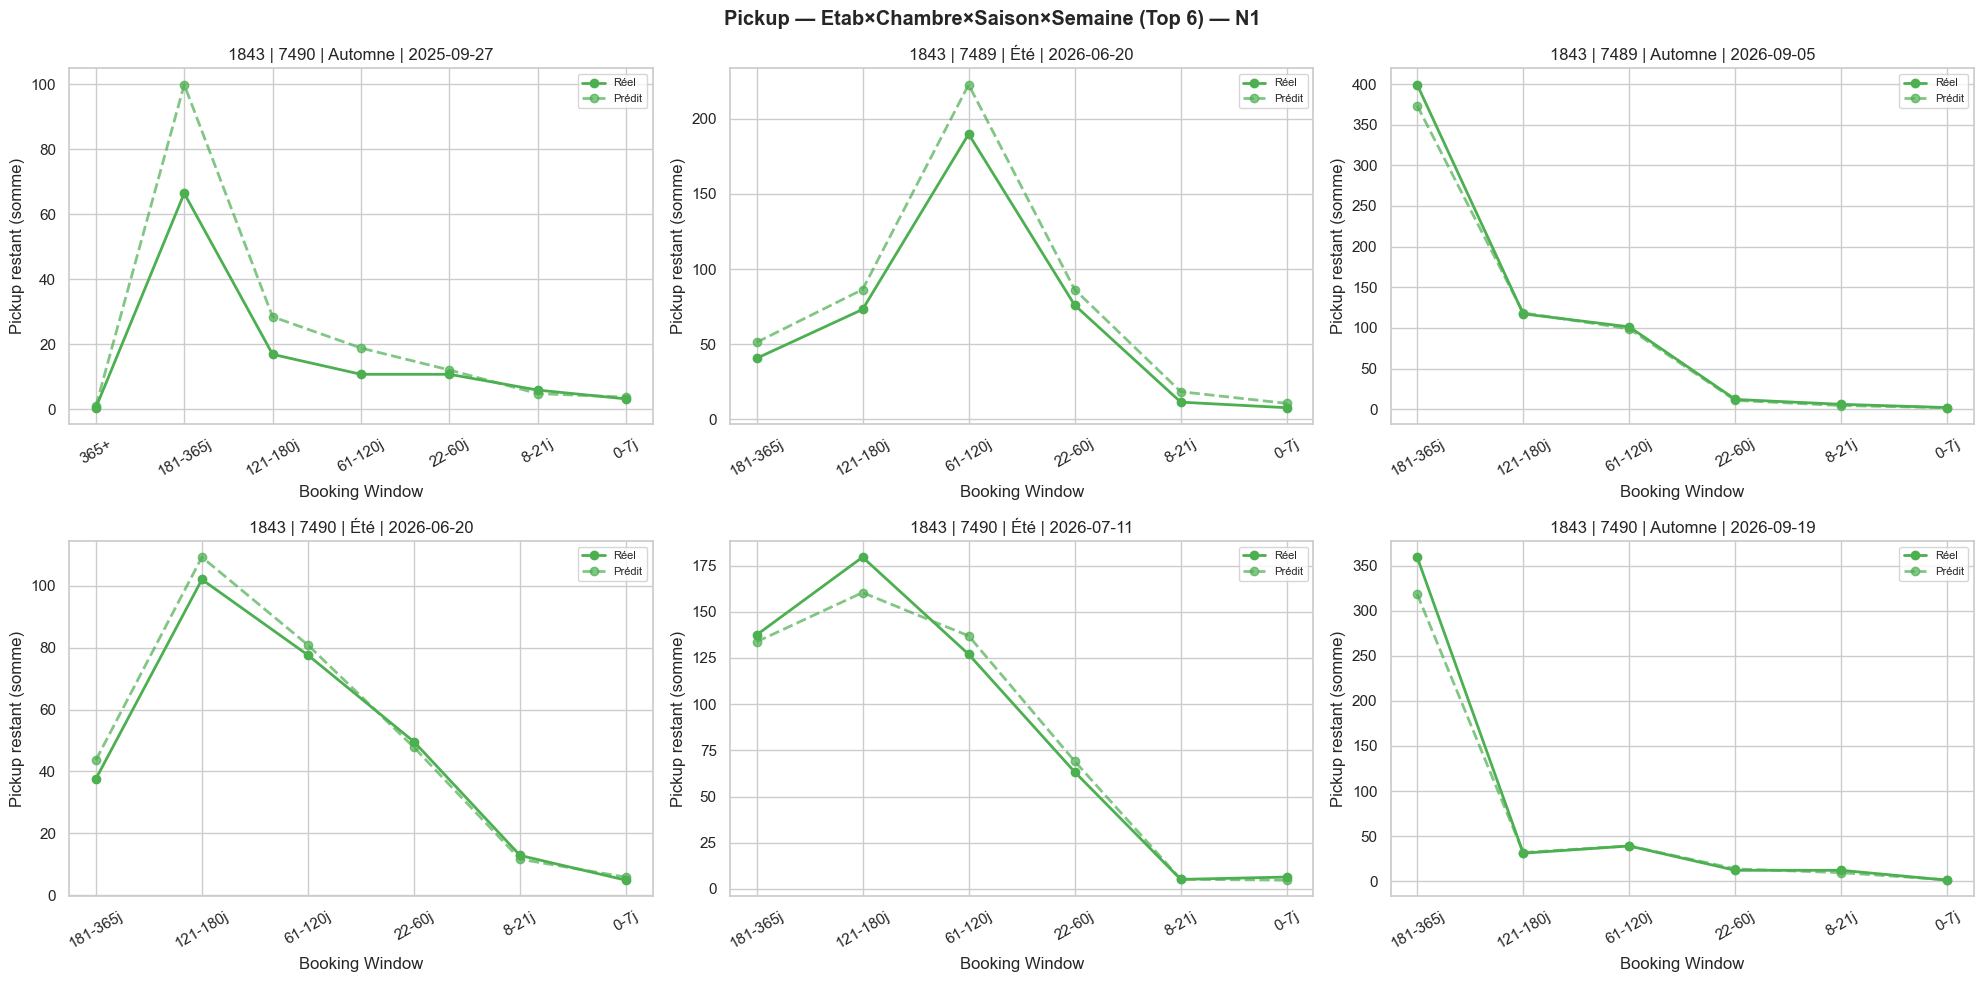

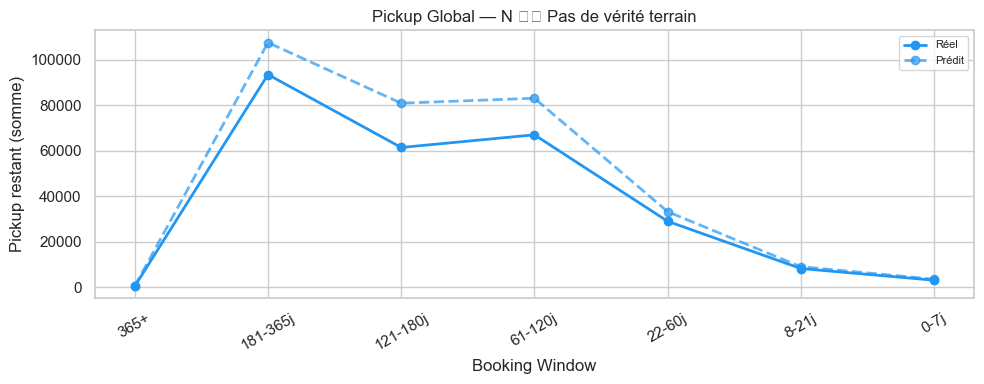

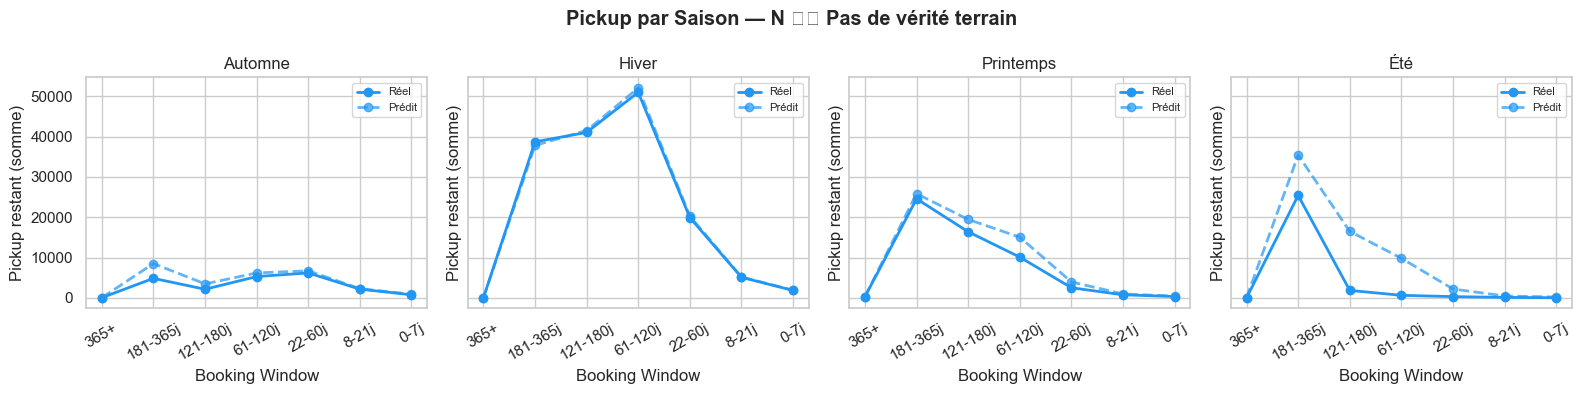

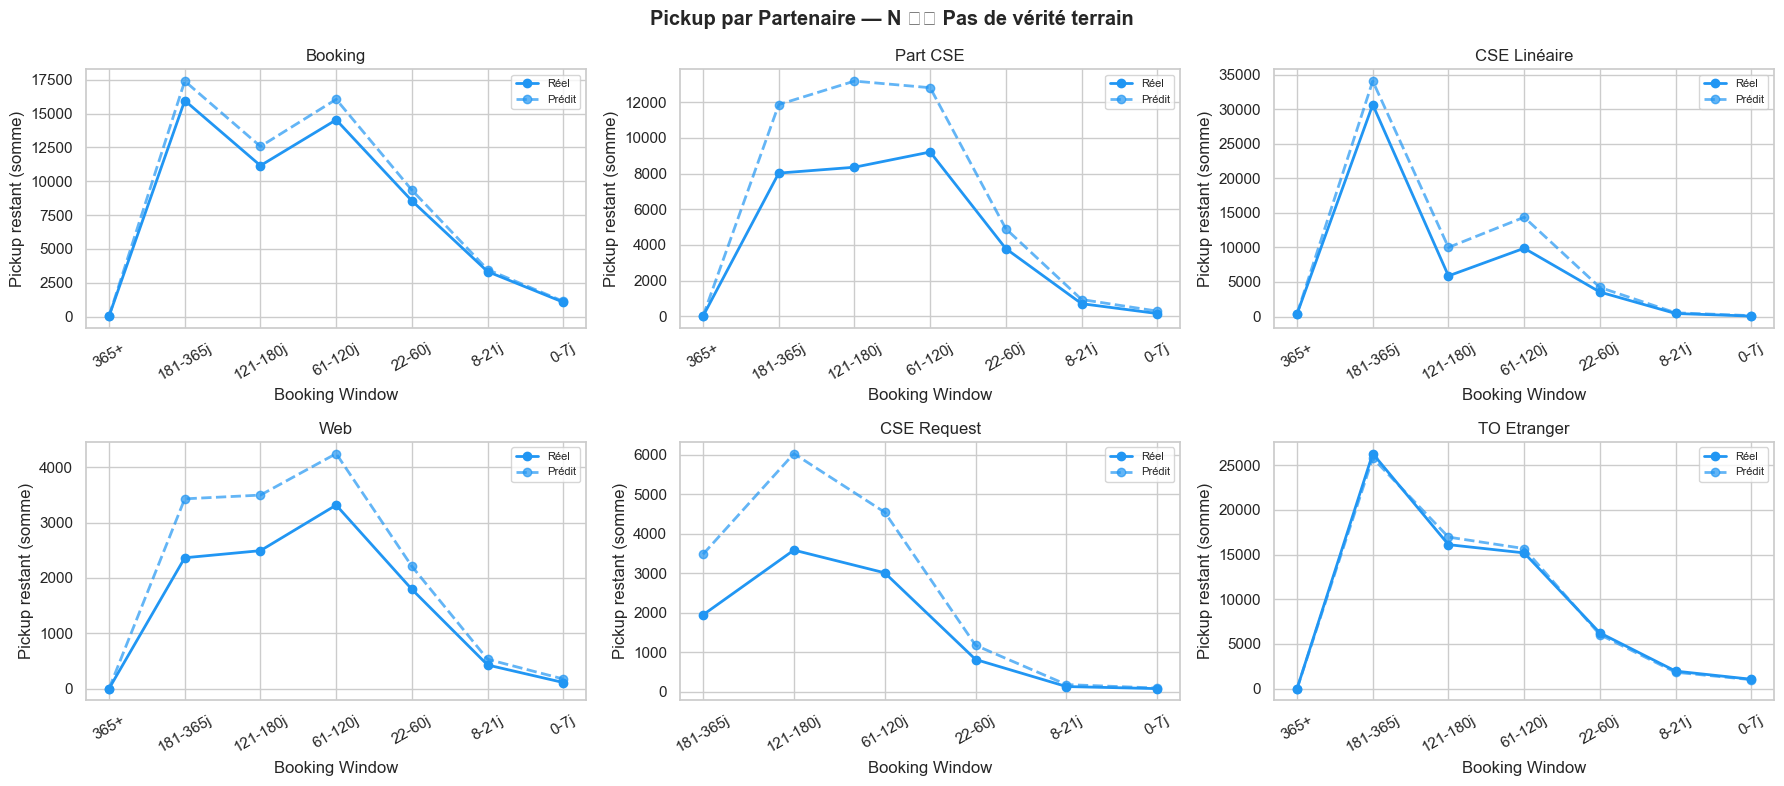

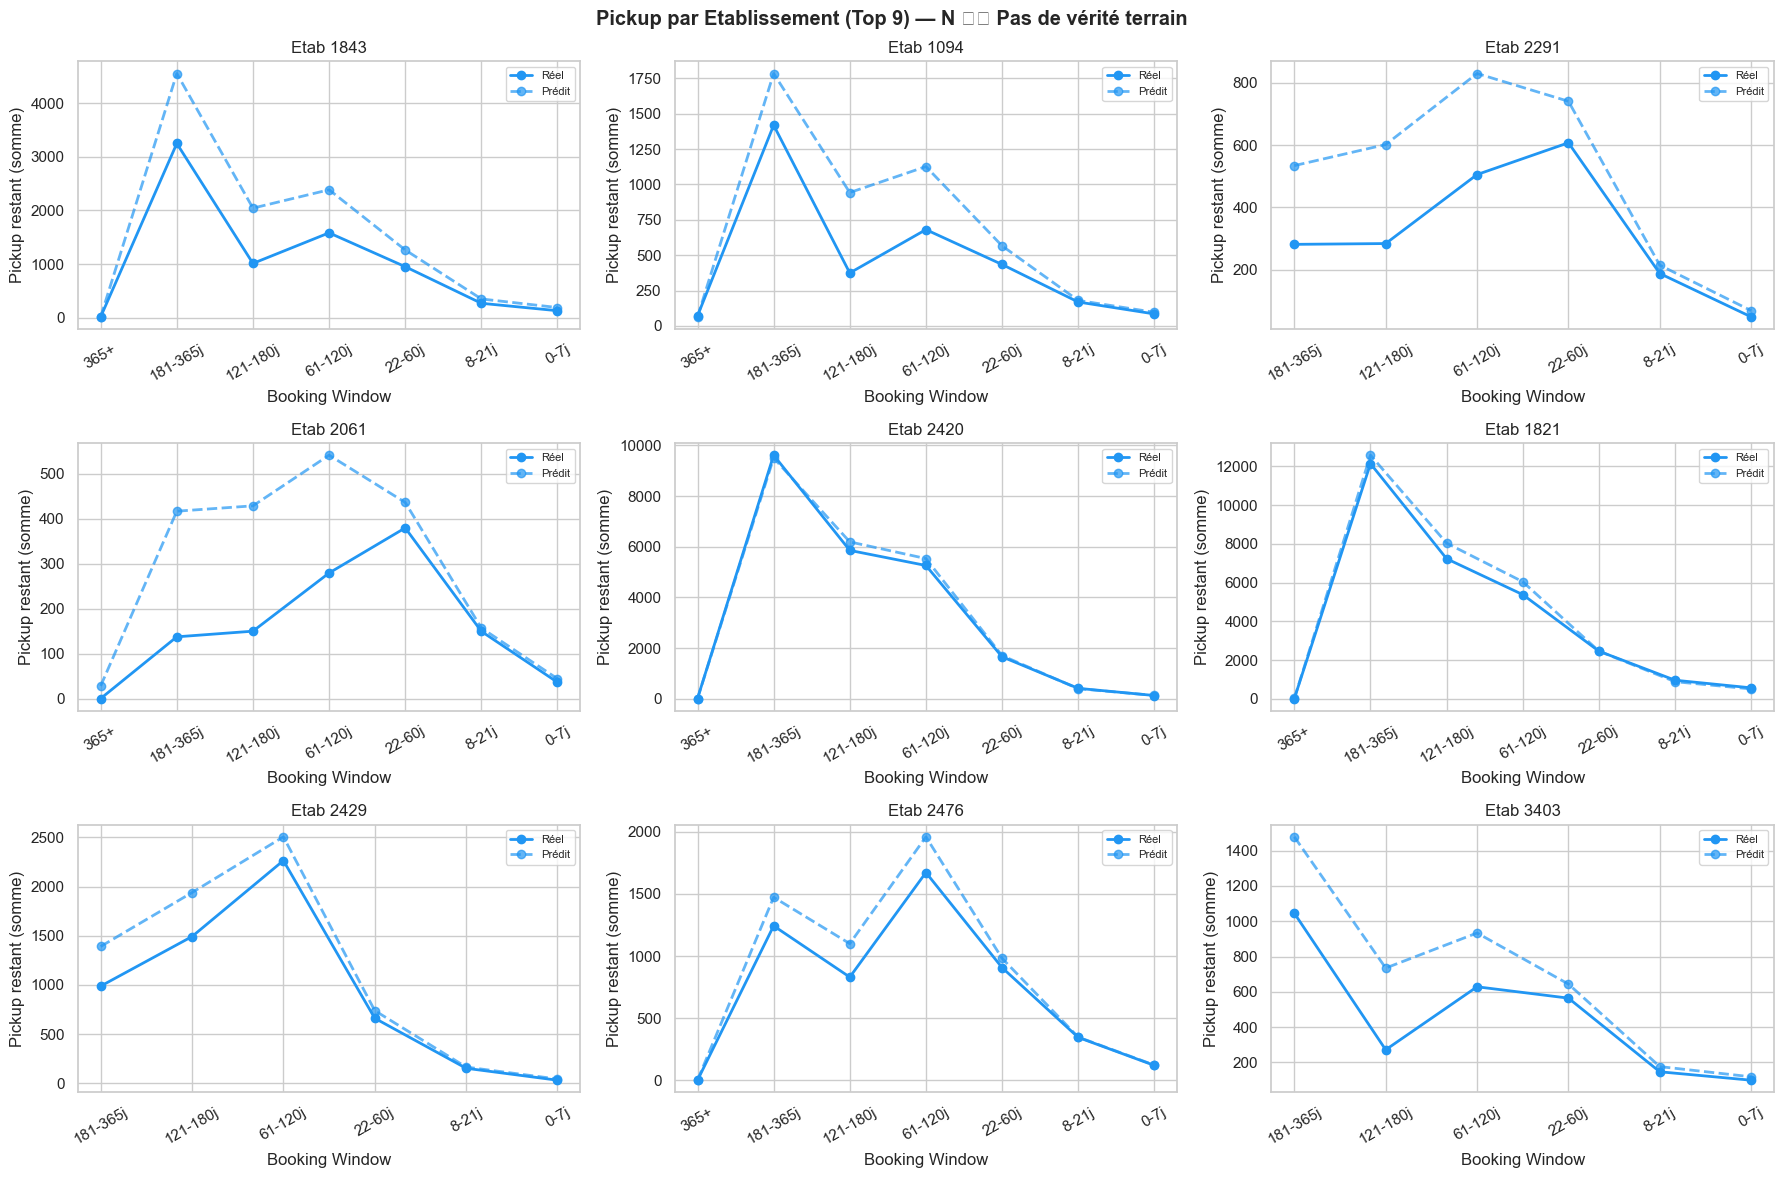

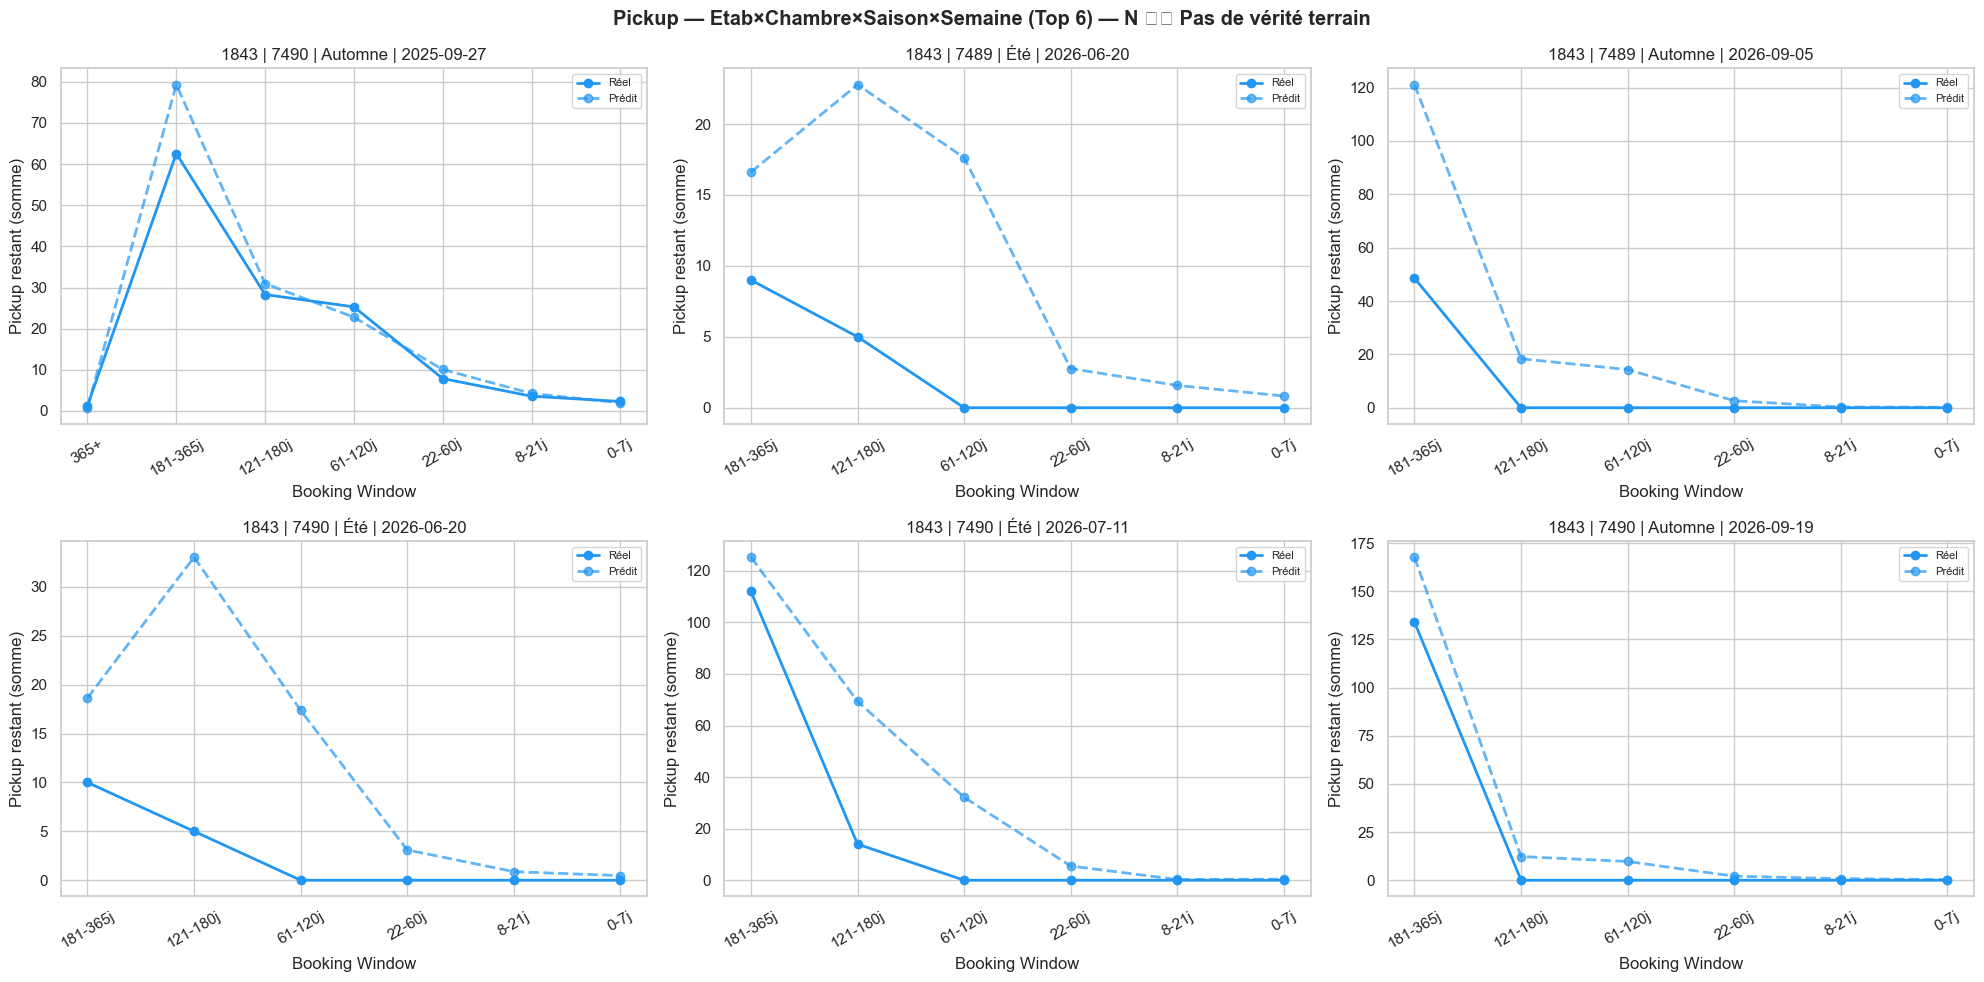

In [30]:
# ============================================================
# Courbes de pickup par Booking Window
# Niveaux : Global, Saison, Partenaire, Etablissement,
#           Etablissement×Chambre×Saison×Semaine
# ============================================================

BW_ORDER  = ['365+', '181-365j', '121-180j', '61-120j', '22-60j', '8-21j', '0-7j']
BW_BINS   = [0, 7, 21, 60, 120, 180, 365, 789]
BW_LABELS = ['0-7j', '8-21j', '22-60j', '61-120j', '121-180j', '181-365j', '365+']

def plot_bw_curve(df, group_col=None, group_val=None, ax=None, title=None, color='#2196F3'):
    if group_col and group_val is not None:
        df = df[df[group_col] == group_val].copy()

    curve = (
        df.groupby('BOOKING_WINDOW', observed=True)
        .agg(PICKUP_REEL=('PICKUP_REEL','sum'), PICKUP_PREDIT=('PICKUP_PREDIT','sum'))
        .reindex(BW_ORDER)
        .reset_index()
    )

    if ax is None:
        _, ax = plt.subplots(figsize=(10, 4))

    ax.plot(curve['BOOKING_WINDOW'], curve['PICKUP_REEL'],
            color=color, lw=2, marker='o', label='Réel')
    ax.plot(curve['BOOKING_WINDOW'], curve['PICKUP_PREDIT'],
            color=color, lw=2, marker='o', linestyle='--', alpha=0.7, label='Prédit')
    ax.set_xlabel('Booking Window')
    ax.set_ylabel('Pickup restant (somme)')
    ax.set_title(title or '')
    ax.tick_params(axis='x', rotation=30)
    ax.legend(fontsize=8)

# ============================================================
# Construire df_eval complet pour chaque fold + N
# ============================================================

# Inclure N dans la boucle (pas de y_true réel pour N → on met NaN)
folds_to_plot = dict(all_preds)  # N2 et N1 issus du CV

# Ajouter N (prédiction production)
mask_N = long_df['ANNEE_MODELE'] == 'N'
X_N    = X.loc[mask_N].drop(columns=[year_col]).copy()
preds_N_arr = np.clip(final_model.predict(X_N), 0, None)
folds_to_plot['N'] = {
    'y_true': long_df.loc[mask_N, 'TARGET_PICKUP_RESTANT'].values,
    'y_pred': preds_N_arr,
    'index' : mask_N[mask_N].index
}

for test_year, fold_data in folds_to_plot.items():
    y_true = fold_data['y_true']
    y_pred = fold_data['y_pred']
    idx    = fold_data['index']
    color  = {'N2':'#FF5722','N1':'#4CAF50','N':'#2196F3'}.get(test_year, '#9C27B0')
    is_N   = (test_year == 'N')

    df_eval = pd.DataFrame({
        'LEAD_TIME'        : long_df.loc[idx, 'LEAD_TIME_JOURS'].values,
        'SEMAINE_SEJOUR'   : long_df.loc[idx, 'SEMAINE_SEJOUR'].values,
        'ID_ETABLISSEMENT' : long_df.loc[idx, 'ID_ETABLISSEMENT'].values,
        'ID_TYPE_CHAMBRE'  : long_df.loc[idx, 'ID_TYPE_CHAMBRE'].values,
        'SAISON'           : long_df.loc[idx, 'SAISON'].values,
        'PARTENAIRE_SEG2'  : long_df.loc[idx, 'PARTENAIRE_SEG2'].values,
        'PICKUP_REEL'      : y_true,
        'PICKUP_PREDIT'    : y_pred,
    })

    df_eval['BOOKING_WINDOW'] = pd.cut(
        df_eval['LEAD_TIME'], bins=BW_BINS, labels=BW_LABELS
    )

    note_N = ' ⚠️ Pas de vérité terrain' if is_N else ''

    # ── 1. GLOBAL ──────────────────────────────────────────────────────
    fig, ax = plt.subplots(figsize=(10, 4))
    plot_bw_curve(df_eval, ax=ax, color=color,
                  title=f'Pickup Global — {test_year}{note_N}')
    plt.tight_layout()
    plt.show()

    # ── 2. PAR SAISON ──────────────────────────────────────────────────
    saisons = sorted(df_eval['SAISON'].dropna().unique())
    fig, axes = plt.subplots(1, len(saisons), figsize=(16, 4), sharey=True)
    fig.suptitle(f'Pickup par Saison — {test_year}{note_N}', fontweight='bold')
    for i, saison in enumerate(saisons):
        plot_bw_curve(df_eval, 'SAISON', saison, ax=axes[i], color=color, title=saison)
    plt.tight_layout()
    plt.show()

    # ── 3. PAR PARTENAIRE ──────────────────────────────────────────────
    partenaires = df_eval['PARTENAIRE_SEG2'].value_counts().head(6).index
    fig, axes = plt.subplots(2, 3, figsize=(18, 8))
    fig.suptitle(f'Pickup par Partenaire — {test_year}{note_N}', fontweight='bold')
    for i, part in enumerate(partenaires):
        plot_bw_curve(df_eval, 'PARTENAIRE_SEG2', part,
                      ax=axes[i//3, i%3], color=color, title=part)
    plt.tight_layout()
    plt.show()

    # ── 4. PAR ETABLISSEMENT (top 9) ───────────────────────────────────
    top_etabs = df_eval['ID_ETABLISSEMENT'].value_counts().head(9).index
    fig, axes = plt.subplots(3, 3, figsize=(18, 12))
    fig.suptitle(f'Pickup par Etablissement (Top 9) — {test_year}{note_N}', fontweight='bold')
    for i, etab in enumerate(top_etabs):
        plot_bw_curve(df_eval, 'ID_ETABLISSEMENT', etab,
                      ax=axes[i//3, i%3], color=color,
                      title=f'Etab {etab}')
    plt.tight_layout()
    plt.show()

    # ── 5. COMBINAISON Etab × Chambre × Saison × Semaine ───────────────
    # Top 6 combinaisons les plus fréquentes
    df_eval['COMBO'] = (
        df_eval['ID_ETABLISSEMENT'].astype(str) + ' | ' +
        df_eval['ID_TYPE_CHAMBRE'].astype(str) + ' | ' +
        df_eval['SAISON'].astype(str) + ' | ' +
        df_eval['SEMAINE_SEJOUR'].astype(str)
    )
    top_combos = df_eval['COMBO'].value_counts().head(6).index

    fig, axes = plt.subplots(2, 3, figsize=(20, 10))
    fig.suptitle(f'Pickup — Etab×Chambre×Saison×Semaine (Top 6) — {test_year}{note_N}',
                 fontweight='bold')
    for i, combo in enumerate(top_combos):
        plot_bw_curve(df_eval, 'COMBO', combo,
                      ax=axes[i//3, i%3], color=color,
                      title=combo[:50])  # tronquer le titre si trop long
    plt.tight_layout()
    plt.show()

In [32]:
# Vérifier
import torch
print(torch.cuda.is_available())  # GPU dispo ?

False


In [34]:
%pip install shap

   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 751.9/751.9 kB 5.4 MB/s eta 0:00:00

   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   ---------------------------------------- 2/2 [shap]

Note: you may need to restart the kernel to use updated packages.


In [35]:
import shap

# ANNEE_MODELE déjà absent de X_final (dropped avant fit)
# donc X_final est prêt directement

explainer = shap.TreeExplainer(final_model)

print(f'Calcul SHAP sur {len(X_final):,} lignes...')
chunk_size = 50_000
shap_chunks = []

for start in range(0, len(X_final), chunk_size):
    end   = min(start + chunk_size, len(X_final))
    chunk = X_final.iloc[start:end]
    sv    = explainer.shap_values(chunk)
    shap_chunks.append(sv)
    print(f'  {end:,} / {len(X_final):,} ({end/len(X_final)*100:.0f}%)')

shap_values = np.vstack(shap_chunks)
print(f'\nShape SHAP values : {shap_values.shape}')
print(f'Mémoire SHAP : {shap_values.nbytes / 1e9:.2f} GB')


Calcul SHAP sur 2,197,749 lignes...
  50,000 / 2,197,749 (2%)
  100,000 / 2,197,749 (5%)
  150,000 / 2,197,749 (7%)
  200,000 / 2,197,749 (9%)
  250,000 / 2,197,749 (11%)
  300,000 / 2,197,749 (14%)
  350,000 / 2,197,749 (16%)
  400,000 / 2,197,749 (18%)
  450,000 / 2,197,749 (20%)
  500,000 / 2,197,749 (23%)
  550,000 / 2,197,749 (25%)
  600,000 / 2,197,749 (27%)
  650,000 / 2,197,749 (30%)
  700,000 / 2,197,749 (32%)
  750,000 / 2,197,749 (34%)
  800,000 / 2,197,749 (36%)
  850,000 / 2,197,749 (39%)
  900,000 / 2,197,749 (41%)
  950,000 / 2,197,749 (43%)
  1,000,000 / 2,197,749 (46%)
  1,050,000 / 2,197,749 (48%)
  1,100,000 / 2,197,749 (50%)
  1,150,000 / 2,197,749 (52%)
  1,200,000 / 2,197,749 (55%)
  1,250,000 / 2,197,749 (57%)
  1,300,000 / 2,197,749 (59%)
  1,350,000 / 2,197,749 (61%)
  1,400,000 / 2,197,749 (64%)
  1,450,000 / 2,197,749 (66%)
  1,500,000 / 2,197,749 (68%)
  1,550,000 / 2,197,749 (71%)
  1,600,000 / 2,197,749 (73%)
  1,650,000 / 2,197,749 (75%)
  1,700,000 / 2,1